# 03 - Train and compare the transistor models (Part A, step 2)

Self-contained notebook, built up in parts:

1. **Harness:** data split, source/drain canonicalisation, target transforms, physics features and the metrics used everywhere else, each with a check.
2. **Baseline models:** polynomial ridge regression and gradient boosting, each tried with and without the Vds-aware target and the physics features.
3. **Neural models and the comparison:** plain MLP and residual MLP, the choice of the target scale `I0`, and the full comparison table (4 model types x 4 cases, validation R2, median and 95th-percentile error).
4. **First version of the final models:** selection of the best model per case, test-set results, predicted-vs-SPICE plots and the four saved model files in `models/`.
5. **Refinement and final models (this part):** after the gate-level evaluation, the two OFF models are retrained with extra samples near the supply rails (generated in notebook 01, section 9); the four final models are scored on the test rows and saved.

One model per case (NMOS ON, NMOS OFF, PMOS ON, PMOS OFF), each predicting the four terminal currents `id, ig, is, ib`.
Model families to compare: residual MLP, plain MLP, gradient boosting (LightGBM) and polynomial ridge regression (plus extra trees as an optional fifth).
Only the CSV files in `data/` (the four datasets and the two `extra_*_off.csv` files) are needed (the symmetry check in section 2 also uses ngspice and the model file, and is skipped if they are missing).

In [1]:
import re
import shutil
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
RESULT_DIR = ROOT / "results"
MODEL_DIR = ROOT / "models"
MODEL_FILE = ROOT / "Model Files-20261105" / "models" / "16nm_HP.pm"
LDIFF = 32e-9                               # AD = AS = W * LDIFF, as in the datasets

CASES = {"nmos_on": "nmos", "nmos_off": "nmos", "pmos_on": "pmos", "pmos_off": "pmos"}
FEATS = ["vdd", "temp", "w", "vd", "vs", "vg", "vb", "vth0", "toxe", "ndep", "u0", "xj"]
TERMS = ["id", "ig", "is", "ib"]            # terminal currents flowing into the device
SPLIT = (0.70, 0.15, 0.15)                  # train / validation / test
SPLIT_SEED = 20261105
I0 = 1e-14                                  # scale of the signed-log transform [A]; chosen in section 12
REL_FLOOR = 1e-15                           # relative errors are only meaningful above the solver floor [A]
SMALL_VDS = 5e-3                            # |Vds| below this is the "small-Vds" region [V]
KB_Q = 8.617333262e-5                       # k/q [V/K]

data = {c: pd.read_csv(DATA_DIR / f"{c}.csv") for c in CASES}
{c: d.shape for c, d in data.items()}

{'nmos_on': (10000, 16),
 'nmos_off': (10000, 16),
 'pmos_on': (10000, 16),
 'pmos_off': (10000, 16)}

## 1. Split
Random 70 / 15 / 15 split with a fixed seed: 7,000 train, 1,500 validation, 1,500 test rows per case. Models are compared on the validation split;
the test split is only used once, for the chosen model.

In [2]:
def split_indices(n, seed=SPLIT_SEED):
    perm = np.random.default_rng(seed).permutation(n)
    n_tr, n_va = int(SPLIT[0] * n), int(SPLIT[1] * n)
    return perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:]


splits = {c: split_indices(len(d)) for c, d in data.items()}
tr, va, te = splits["nmos_on"]
print("rows per split:", len(tr), len(va), len(te), "| disjoint:", len(set(tr) | set(va) | set(te)) == len(data["nmos_on"]))

rows per split: 7000 1500 1500 | disjoint: True


## 2. Source/drain canonicalisation
The device is symmetric in drain and source (the netlists use `AD = AS`), so swapping the two terminals gives the same device: `id` and `is` trade places and `ig`, `ib` are unchanged.
Drain and source are drawn independently, so half the samples sit in each orientation. Mapping every sample to one orientation (**Vds >= 0 for NMOS, Vsd >= 0 for PMOS**) fixes the sign of `id` and `is` per case, and removes the sign change at Vd = Vs from the learning problem.
The check below compares real SPICE results for the two orientations (nominal process, W = 32 nm).

In [3]:
def canonicalize(df, device):
    """Swap drain and source where needed so that Vds >= 0 (NMOS) or Vsd >= 0 (PMOS); id and is swap with them."""
    d = df.copy()
    swap = (d["vd"] < d["vs"]) if device == "nmos" else (d["vd"] > d["vs"])
    d.loc[swap, ["vd", "vs"]] = d.loc[swap, ["vs", "vd"]].to_numpy()
    d.loc[swap, ["id", "is"]] = d.loc[swap, ["is", "id"]].to_numpy()
    return d, swap


canon, swapped = {}, {}
for c, dev in CASES.items():
    canon[c], swapped[c] = canonicalize(data[c], dev)
print("fraction of rows swapped:", {c: round(float(s.mean()), 3) for c, s in swapped.items()})

# canonicalising twice changes nothing, and the orientation is now fixed
again, _ = canonicalize(canon["nmos_on"], "nmos")
print("idempotent:", bool(again.equals(canon["nmos_on"])))

sign = pd.DataFrame({c: {t: f"{(d.iloc[splits[c][0]][t] > 0).mean():.3f}" for t in TERMS} for c, d in canon.items()})
print("fraction of positive values after canonicalisation (training rows only):")
sign

fraction of rows swapped: {'nmos_on': 0.505, 'nmos_off': 0.498, 'pmos_on': 0.5, 'pmos_off': 0.498}
idempotent: True
fraction of positive values after canonicalisation (training rows only):


,nmos_on,nmos_off,pmos_on,pmos_off
id,1.000,1.000,0.000,0.000
ig,1.000,0.000,0.000,0.912
is,0.000,0.571,1.000,0.650
ib,0.000,0.002,1.000,0.733


After canonicalisation the signs of all four currents are fixed in the ON cases. In the OFF cases `is`, `ib` and (PMOS) `ig` still change sign: they are small and set by the balance of the channel, gate and body components. The signed-log target is therefore still needed.

In [4]:
SPICE_OPTIONS = ".options gmin=1e-18 abstol=1e-18 reltol=1e-6 vntol=1e-9"
VDD = 0.9
BIAS = {  # (vg, vb) per case
    "nmos_on": (VDD, 0.0), "nmos_off": (0.0, 0.0), "pmos_on": (0.0, VDD), "pmos_off": (VDD, VDD)}


def run_ngspice(netlist, name="symmetry.cir"):
    build = ROOT / "build"
    build.mkdir(exist_ok=True)
    shutil.copyfile(MODEL_FILE, build / MODEL_FILE.name)
    (build / name).write_text(netlist, newline="\n")
    if shutil.which("ngspice"):
        return subprocess.run(["ngspice", "-b", name], cwd=build, capture_output=True, text=True).stdout
    p = build.resolve()
    wsl = "/mnt/" + p.drive.rstrip(":").lower() + "/" + "/".join(p.parts[1:])
    r = subprocess.run(["wsl", "-e", "bash", "-c", f"cd '{wsl}' && ngspice -b {name} 2>/dev/null"], capture_output=True, text=True)
    return r.stdout.replace("\x00", "")


def symmetry_netlist():
    lines = ["* drain/source symmetry check", f".include {MODEL_FILE.name}", SPICE_OPTIONS]
    runs = []
    for c, dev in CASES.items():
        vg, vb = BIAS[c]
        for k, (vd, vs) in enumerate([(0.5, 0.2), (0.2, 0.5)]):
            t = f"{c}_{k}"
            w = 32e-9
            lines.append(f"M{t} d{t} g{t} s{t} b{t} {dev} W={w:.6g} L=16n AD={w * LDIFF:.6g} AS={w * LDIFF:.6g}")
            lines += [f"Vd{t} d{t} 0 {vd}", f"Vg{t} g{t} 0 {vg}", f"Vs{t} s{t} 0 {vs}", f"Vb{t} b{t} 0 {vb}"]
            runs.append(t)
    lines += [".control", "set numdgt = 15", "set temp = 27", "op"]
    lines += ["print " + " ".join(f"i(v{x}{t})" for x in "dgsb") for t in runs]
    lines += [".endc", ".end", ""]
    return "\n".join(lines), runs


try:
    text, runs = symmetry_netlist()
    out = run_ngspice(text)
    vals = [-float(v) for v in re.findall(r"^i\(v[dgsb]\w*\) = (\S+)$", out, re.M)]
    assert len(vals) == 4 * len(runs), "ngspice did not return all results"
    cur = {t: vals[4 * k:4 * k + 4] for k, t in enumerate(runs)}
    rows = []
    for c in CASES:
        a, b = cur[f"{c}_0"], cur[f"{c}_1"]            # (id, ig, is, ib) before and after swapping drain and source
        rows.append(dict(case=c, id_vs_is_swapped=abs(a[0] - b[2]) / abs(a[0]), is_vs_id_swapped=abs(a[2] - b[0]) / abs(a[2]),
                         ig=abs(a[1] - b[1]) / abs(a[1]), ib=abs(a[3] - b[3]) / abs(a[3])))
    sym = pd.DataFrame(rows).set_index("case")
    print("relative mismatch between the two orientations (0 = perfectly symmetric):")
    display(sym.style.format("{:.1e}"))
except Exception as e:                                  # ngspice or the model file not available
    print("symmetry check skipped:", e)

relative mismatch between the two orientations (0 = perfectly symmetric):


,id_vs_is_swapped,is_vs_id_swapped,ig,ib
case,,,,
nmos_on,1.5e-14,1.7e-14,0.0e+00,1.8e-10
nmos_off,5.3e-08,7.0e-06,0.0e+00,1.9e-05
pmos_on,1.2e-13,1.2e-13,2.7e-15,0.0e+00
pmos_off,1.4e-03,1.7e-04,0.0e+00,0.0e+00


## 3. Target transforms
The currents span about 11 decades and (before canonicalisation) change sign, so the models are trained on a transformed target.

* **Signed log:** `y = arcsinh(I / I0)` with `I0 = 1e-14 A` (chosen in section 12: the simulator resolves small currents only to about 4.4e-16 A, and a smaller `I0` makes the models chase that rounding). For `|I| >> I0` it equals `ln(2|I|/I0)`, so an error in `y` is a relative error in `I`; it is linear near zero and keeps the sign.
* **Vds-aware factor (id and is only):** the BSIM sub-threshold current carries the factor `1 - exp(-Vds / V_therm)` (lecture slide 10), with `V_therm = kT/q`. At `|Vds|` of 1 uV to a few mV, where the ON devices sit inside a gate, the current is proportional to `Vds` and crosses zero. Dividing by the factor leaves a smooth quantity that does not vanish at `Vds -> 0`:
  `y = arcsinh((I / factor) / I0)`, inverted by `I = I0 sinh(y) * factor`.

**Caveat (checked below and on the validation rows):** the factor only helps where the current really is proportional to Vds at small Vds. In the ON cases the channel is in its linear region, so it should be; in the OFF cases `id` also contains Vds-independent components (gate-induced and tunnelling currents leaving through the drain), so dividing by the factor over-corrects. Using it is therefore a per-case choice, made on validation.

In [5]:
def vds_factor(vds, temp_c):
    """1 - exp(-|Vds| / vT) with vT = kT/q; expm1 keeps it accurate for tiny Vds."""
    vt = KB_Q * (np.asarray(temp_c) + 273.15)
    return np.clip(-np.expm1(-np.abs(vds) / vt), 1e-12, None)


def encode(currents, vds, temp_c, vds_aware=True, i0=None):
    """Currents (n, 4) in the order id, ig, is, ib -> transformed targets (n, 4)."""
    i0 = I0 if i0 is None else i0
    cur = np.asarray(currents, dtype=float).copy()
    if vds_aware:
        f = vds_factor(vds, temp_c)
        cur[:, 0] /= f
        cur[:, 2] /= f
    return np.arcsinh(cur / i0)


def decode(y, vds, temp_c, vds_aware=True, i0=None):
    i0 = I0 if i0 is None else i0
    cur = i0 * np.sinh(np.asarray(y, dtype=float))
    if vds_aware:
        f = vds_factor(vds, temp_c)
        cur[:, 0] *= f
        cur[:, 2] *= f
    return cur


rows = []
for c, dev in CASES.items():
    d = canon[c]
    vds = (d["vd"] - d["vs"]).abs().to_numpy()
    cur = d[TERMS].to_numpy()
    for aware in (False, True):
        back = decode(encode(cur, vds, d["temp"].to_numpy(), aware), vds, d["temp"].to_numpy(), aware)
        m = np.abs(cur) > 0
        rows.append(dict(case=c, vds_aware=aware, max_roundtrip_rel_error=float(np.max(np.abs(back[m] - cur[m]) / np.abs(cur[m])))))
pd.DataFrame(rows)

,case,vds_aware,max_roundtrip_rel_error
0,nmos_on,False,2.062707e-15
1,nmos_on,True,2.043435e-15
2,nmos_off,False,1.896939e-15
3,nmos_off,True,1.833538e-15
4,pmos_on,False,2.006573e-15
5,pmos_on,True,2.122813e-15
6,pmos_off,False,1.985436e-15
7,pmos_off,True,1.884718e-15


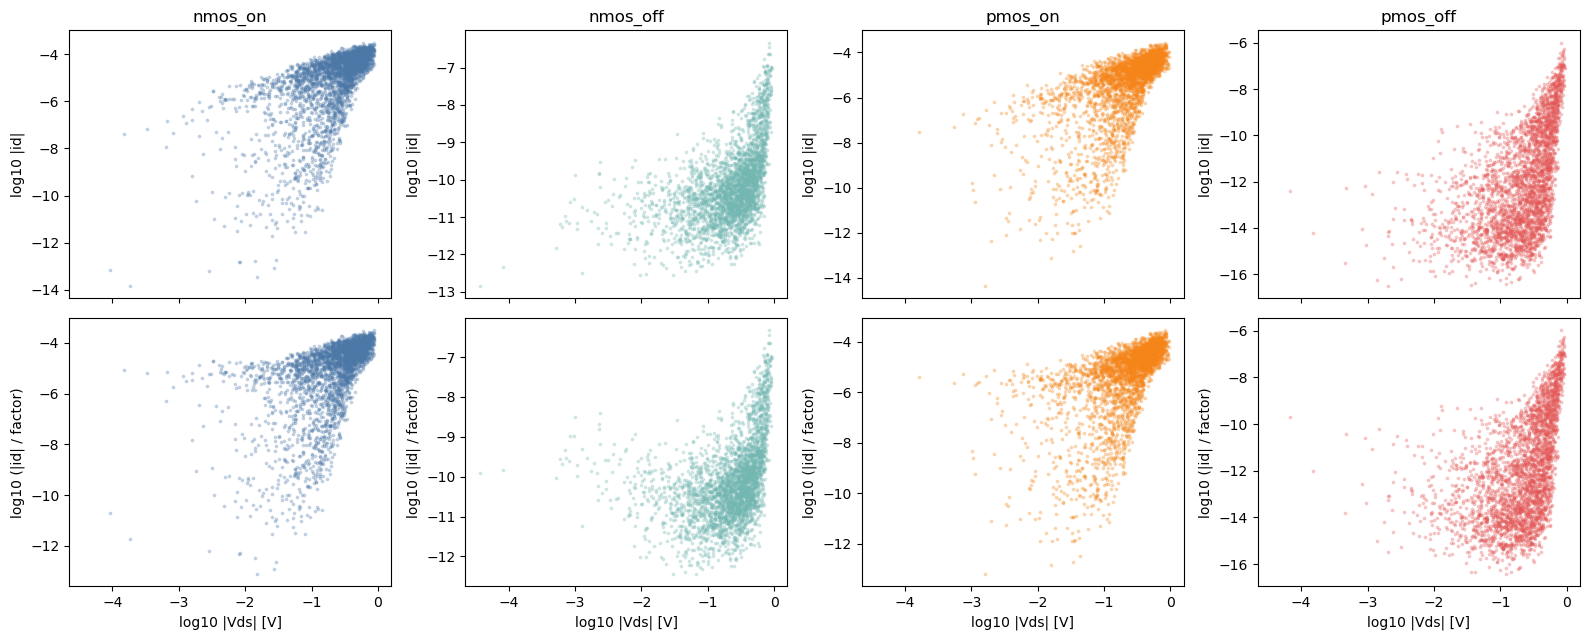

slope of log10|id| vs log10|Vds| for |Vds| < 10 mV (1 = proportional to Vds, 0 = independent of Vds):


,rows_below_10mV,slope_raw,slope_with_factor
case,,,
nmos_on,157,1.241541,0.300257
nmos_off,164,0.376887,-0.597780
pmos_on,173,0.389850,-0.548509
pmos_off,160,-0.205366,-1.160381


In [6]:
fig, ax = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
slopes = []
for k, (c, dev) in enumerate(CASES.items()):
    d = canon[c].iloc[splits[c][0]]                      # training rows only: nothing here may depend on validation or test rows
    vds = (d["vd"] - d["vs"]).abs().to_numpy()
    f = vds_factor(vds, d["temp"].to_numpy())
    raw, scaled = np.log10(np.abs(d["id"].to_numpy())), np.log10(np.abs(d["id"].to_numpy()) / f)
    sel = np.random.default_rng(0).choice(len(d), size=3000, replace=False)
    for row, (y, label) in enumerate([(raw, "log10 |id|"), (scaled, "log10 (|id| / factor)")]):
        ax[row, k].scatter(np.log10(vds[sel]), y[sel], s=3, alpha=0.25, color=["#4C78A8", "#72B7B2", "#F58518", "#E45756"][k])
        ax[row, k].set_ylabel(label)
    ax[1, k].set_xlabel("log10 |Vds| [V]")
    ax[0, k].set_title(c)
    small = vds < 10e-3
    slopes.append(dict(case=c, rows_below_10mV=int(small.sum()),
                       slope_raw=np.polyfit(np.log10(vds[small]), raw[small], 1)[0],
                       slope_with_factor=np.polyfit(np.log10(vds[small]), scaled[small], 1)[0]))
fig.tight_layout()
fig.savefig(RESULT_DIR / "vds_aware_target.png", dpi=110)
plt.show()
print("slope of log10|id| vs log10|Vds| for |Vds| < 10 mV (1 = proportional to Vds, 0 = independent of Vds):")
pd.DataFrame(slopes).set_index("case")

Reading the slopes (training rows only; about 160 rows per case lie below 10 mV and all other inputs vary freely, so the numbers are rough and noisy): in NMOS ON the current goes from proportional to Vds (1.24) to nearly independent of it (0.30) with the factor. In the other three cases the raw slope is weak (0.38, 0.39 and -0.21) and the factor over-corrects it (-0.60, -0.55 and -1.16), which for the OFF cases fits the Vds-independent components of the OFF-state `id`. The slopes alone are too noisy to decide the ON cases, so the Vds-aware target is a per-case option chosen on the validation rows (section 10).

## 4. Features
Raw inputs plus quantities built from the known device physics (source-referenced voltages; for PMOS the sign is mirrored so both device types see the same regime):
`q/kT`, `Vgs`, `Vds`, `Vbs`, `Vgd`, the overdrive `(Vgs - Vth)/vT`, `Vds/vT` and `ln W`. Models are free to use either set; the comparison will show which helps.

In [7]:
def make_features(d, device):
    sgn = 1.0 if device == "nmos" else -1.0
    vt = KB_Q * (d["temp"] + 273.15)
    vgs, vds, vbs, vgd = sgn * (d["vg"] - d["vs"]), sgn * (d["vd"] - d["vs"]), sgn * (d["vb"] - d["vs"]), sgn * (d["vg"] - d["vd"])
    X = d[FEATS].copy()
    X["inv_vt"] = 1.0 / vt
    X["vgs"], X["vds"], X["vbs"], X["vgd"] = vgs, vds, vbs, vgd
    X["vov_vt"] = (vgs - sgn * d["vth0"]) / vt          # (Vgs - Vth)/vT; sgn*vth0 is the threshold magnitude for both types
    X["vds_vt"] = vds / vt
    X["log_w"] = np.log(d["w"])
    return X


X_nmos = make_features(canon["nmos_on"], "nmos")
X_pmos = make_features(canon["pmos_on"], "pmos")
print(f"{X_nmos.shape[1]} features per row:", list(X_nmos.columns))
print("Vds >= 0 after canonicalisation (NMOS, PMOS):", bool((X_nmos["vds"] >= 0).all()), bool((X_pmos["vds"] >= 0).all()))
X_nmos.describe().T[["min", "max"]]

20 features per row: ['vdd', 'temp', 'w', 'vd', 'vs', 'vg', 'vb', 'vth0', 'toxe', 'ndep', 'u0', 'xj', 'inv_vt', 'vgs', 'vds', 'vbs', 'vgd', 'vov_vt', 'vds_vt', 'log_w']
Vds >= 0 after canonicalisation (NMOS, PMOS): True True


,min,max
vdd,8.100015e-01,9.899901e-01
temp,-3.997698e+01,1.249639e+02
w,1.604659e-08,1.279977e-07
vd,8.020292e-03,9.858975e-01
vs,4.262181e-06,9.459957e-01
vg,8.100015e-01,9.899901e-01
vb,0.000000e+00,0.000000e+00
vth0,4.316953e-01,5.276100e-01
toxe,8.550239e-10,1.044929e-09
ndep,6.300173e+18,7.699886e+18


## 5. Metrics
Every model is scored the same way, per terminal:
* **R2** on the signed-log target (the scale the models are trained on) and on the linear current,
* **median** and **95th-percentile relative error** `|pred - true| / |true|` (the project text does not define "error"; this is the definition used everywhere in this work), on rows with `|true| >= 1e-15 A`. Below 1e-15 A the currents are at the level of the solver floor (the Kirchhoff residual of the data is up to 1.5e-15 A) and a relative error means nothing, and such currents are negligible next to gate leakages, which are of the order of 1e-10 A or more. The share of rows left out is reported with every table (`frac_below_floor`; it is large only for `ib` and PMOS-OFF `ig`),
* the same errors restricted to the **small-Vds region** (`|Vds| < 5 mV`), where the gate-level ON devices operate.

In [8]:
def score(true, pred, vds, i0=None):
    """Per-terminal metrics; true and pred are (n, 4) currents in the order id, ig, is, ib."""
    i0 = I0 if i0 is None else i0
    true, pred, vds = np.asarray(true), np.asarray(pred), np.asarray(vds)
    rows = []
    for k, t in enumerate(TERMS):
        yt, yp = np.arcsinh(true[:, k] / i0), np.arcsinh(pred[:, k] / i0)
        r2_log = 1 - ((yt - yp) ** 2).sum() / ((yt - yt.mean()) ** 2).sum()
        r2_lin = 1 - ((true[:, k] - pred[:, k]) ** 2).sum() / ((true[:, k] - true[:, k].mean()) ** 2).sum()
        m = np.abs(true[:, k]) >= REL_FLOOR
        rel = np.abs(pred[m, k] - true[m, k]) / np.abs(true[m, k])
        ms = m & (vds < SMALL_VDS)
        rel_s = np.abs(pred[ms, k] - true[ms, k]) / np.abs(true[ms, k])
        rows.append(dict(terminal=t, r2_log=r2_log, r2_lin=r2_lin, median_rel=np.median(rel), p95_rel=np.percentile(rel, 95), n_used=int(m.sum()), frac_below_floor=float(1 - m.mean()),
                         median_rel_small_vds=np.median(rel_s) if len(rel_s) else np.nan,
                         p95_rel_small_vds=np.percentile(rel_s, 95) if len(rel_s) else np.nan, n_small_vds=int(ms.sum())))
    return pd.DataFrame(rows).set_index("terminal")


# the metrics must behave on known inputs: a perfect prediction scores 0 error, a +1 % prediction scores exactly 1 %
va_idx = splits["nmos_on"][1]
d = canon["nmos_on"].iloc[va_idx]
true = d[TERMS].to_numpy()
vds = (d["vd"] - d["vs"]).abs().to_numpy()
perfect, off_by_1pct = score(true, true, vds), score(true, true * 1.01, vds)
print("perfect prediction: max median error =", perfect["median_rel"].max(), "| R2 (log) =", perfect["r2_log"].min())
print("+1 % prediction:   median error =", off_by_1pct["median_rel"].round(6).tolist(), "(expected 0.01)")
off_by_1pct

perfect prediction: max median error = 0.0 | R2 (log) = 1.0
+1 % prediction:   median error = [0.01, 0.01, 0.01, 0.01] (expected 0.01)


,r2_log,r2_lin,median_rel,p95_rel,n_used,frac_below_floor,median_rel_small_vds,p95_rel_small_vds,n_small_vds
terminal,,,,,,,,,
id,0.999993,0.999839,0.01,0.01,1500,0.000000,0.01,0.01,19
ig,0.999983,0.999891,0.01,0.01,1500,0.000000,0.01,0.01,19
is,0.999993,0.999839,0.01,0.01,1500,0.000000,0.01,0.01,19
ib,0.999990,0.999898,0.01,0.01,1493,0.004667,0.01,0.01,19


## Summary of the harness
* 70/15/15 split with a fixed seed, identical for every model.
* Canonicalisation to Vds >= 0 (NMOS) / Vsd >= 0 (PMOS) fixes the signs of all four currents in the ON cases; in the OFF cases `is`, `ib` and (PMOS) `ig` still change sign, so the signed-log target stays. The SPICE check shows the device is symmetric in D/S (worst mismatch 1.4e-3, usually far smaller).
* Targets: signed log with the scale `I0 = 1e-14 A` (chosen in section 12.1), optionally with the Vds-aware factor for `id` and `is` (round trip exact to floating-point precision). The log-log slopes are too noisy (about 160 rows below 10 mV) to decide where it helps, so it is a per-case option chosen on the validation rows.
* Features: raw inputs plus physics-based ones.
* Metrics: R2 and relative errors per terminal, plus the small-Vds region and the share of rows below the 1e-15 A floor, validated on known inputs.
* Everything that guides a design choice (slopes, signs) is computed on the training rows only; the test rows are not used until part 4.

## 6. Model-ready data
A model sees one **option set**: `vds_aware` (target transform of section 3 on or off) and `physics` (the 8 extra features of section 4 on or off). `prepare` builds the standardised inputs and targets for one case and one option set. The scalers are fitted on the **training rows only**, so nothing from the validation or test rows leaks into the models.

Every model is fitted on the training rows. The validation rows are used to pick the option set and, for gradient boosting, the number of trees. The **test rows are not touched in this part**; they are used once in part 4.

In [9]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler


def prepare(case, vds_aware, physics, i0=None):
    """Standardised inputs X and targets Y for one case and one option set (scalers fitted on the training rows)."""
    i0 = I0 if i0 is None else i0
    d = canon[case]
    X = make_features(d, CASES[case])
    if not physics:
        X = X[FEATS]
    vds = (d["vd"] - d["vs"]).abs().to_numpy()
    temp = d["temp"].to_numpy()
    cur = d[TERMS].to_numpy()
    y = encode(cur, vds, temp, vds_aware, i0)
    tr, va, te = splits[case]
    sx, sy = StandardScaler().fit(X.iloc[tr]), StandardScaler().fit(y[tr])
    return dict(case=case, vds_aware=vds_aware, physics=physics, i0=i0, X=sx.transform(X), Y=sy.transform(y), sx=sx, sy=sy,
                vds=vds, temp=temp, cur=cur, tr=tr, va=va, te=te, columns=list(X.columns))


def to_currents(P, prep, idx):
    """Standardised model output for the rows idx -> currents (n, 4) in A (canonical orientation)."""
    return decode(prep["sy"].inverse_transform(P), prep["vds"][idx], prep["temp"][idx], prep["vds_aware"], prep["i0"])


# checks: scalers are fitted on the training rows, and the standardised targets decode back to the SPICE currents
for aware in (False, True):
    p = prepare("nmos_on", aware, True)
    back = to_currents(p["Y"][p["va"]], p, p["va"])
    m = np.abs(p["cur"][p["va"]]) > 0
    err = np.max(np.abs(back[m] - p["cur"][p["va"]][m]) / np.abs(p["cur"][p["va"]][m]))
    print(f"vds_aware={aware}: train mean {p['X'][p['tr']].mean():+.1e}, train std {p['X'][p['tr']].std(axis=0).mean():.3f}, "
          f"{p['X'].shape[1]} features, decode round trip max rel. error {err:.1e}")

vds_aware=False: train mean +4.1e-16, train std 0.950, 20 features, decode round trip max rel. error 6.3e-15
vds_aware=True: train mean +4.1e-16, train std 0.950, 20 features, decode round trip max rel. error 6.3e-15


## 7. Selection rule and common interface
All model families share one interface (`fit(X, Y, X_val, Y_val)` and `predict(X)` on standardised arrays), so the neural models of part 3 can be added to the same table.

**Selection rule (validation rows only):** the option set and settings with the lowest **mean over the four terminals of the median relative error** (|I| >= 1e-15 A). The median error is the closest of the metrics to the 1 % goal of the project; the 95th percentile and the R2 of the signed-log currents are reported next to it, and the table below also checks whether R2 would have chosen differently.

In [10]:
from sklearn.linear_model import RidgeCV
import lightgbm as lgb
import time

RIDGE_ALPHAS = np.logspace(-6, 3, 19)
MODEL_SEED = 0                              # seed of every model fit in this notebook (the data split uses SPLIT_SEED)


class PolyRidge:
    """Polynomial features of the standardised inputs + ridge regression; the penalty is chosen per terminal by
    leave-one-out cross-validation on the training rows (no validation rows involved)."""

    def __init__(self, degree):
        self.degree = degree

    def fit(self, X, Y, X_val=None, Y_val=None):
        self.poly = PolynomialFeatures(self.degree, include_bias=False)
        self.ridge = RidgeCV(alphas=RIDGE_ALPHAS, alpha_per_target=True).fit(self.poly.fit_transform(X), Y)
        self.setting = f"degree={self.degree}, alpha={[float(f'{a:.3g}') for a in self.ridge.alpha_]}"
        return self

    def predict(self, X):
        return self.ridge.predict(self.poly.transform(X))


class GradientBoosting:
    """One LightGBM regressor per terminal; early stopping on the validation rows chooses the number of trees."""

    def __init__(self, max_trees=3000, learning_rate=0.05):
        self.max_trees, self.learning_rate = max_trees, learning_rate

    def fit(self, X, Y, X_val, Y_val):
        self.models = []
        for k in range(Y.shape[1]):
            m = lgb.LGBMRegressor(n_estimators=self.max_trees, learning_rate=self.learning_rate, num_leaves=31, min_child_samples=10,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.9, random_state=MODEL_SEED, deterministic=True,
                                  force_row_wise=True, n_jobs=8, verbosity=-1)
            m.fit(X, Y[:, k], eval_set=[(X_val, Y_val[:, k])], callbacks=[lgb.early_stopping(100, verbose=False)])
            self.models.append(m)
        self.setting = f"trees={[m.best_iteration_ for m in self.models]}"
        return self

    def predict(self, X):
        return np.column_stack([m.predict(X) for m in self.models])


def evaluate(model, prep, family):
    """Validation-set metrics of a fitted model, one row of the comparison table."""
    va = prep["va"]
    s = score(prep["cur"][va], to_currents(model.predict(prep["X"][va]), prep, va), prep["vds"][va], prep["i0"])
    row = dict(case=prep["case"], family=family, vds_aware=prep["vds_aware"], physics=prep["physics"], setting=model.setting,
               r2_log=s["r2_log"].mean(), r2_lin=s["r2_lin"].mean(), median_rel=s["median_rel"].mean(), p95_rel=s["p95_rel"].mean(),
               median_rel_small_vds=s["median_rel_small_vds"].mean())
    metrics = ("r2_log", "r2_lin", "median_rel", "p95_rel", "median_rel_small_vds", "n_small_vds", "n_used", "frac_below_floor")
    row.update({f"{m}_{t}": s.loc[t, m] for t in TERMS for m in metrics})      # all metrics per terminal
    return row


OPTIONS = [(a, p) for a in (False, True) for p in (False, True)]
prep_cache = {(c, a, p): prepare(c, a, p) for c in CASES for a, p in OPTIONS}
rows, best = [], {}       # best[(case, family)] = (median_rel, fitted model, option set)


def register(family, prep, model):
    """Evaluate a fitted model on the validation rows, add a row to the table, and keep the model if it is the best of its family and case so far."""
    row = evaluate(model, prep, family)
    rows.append(row)
    key = (prep["case"], family)
    if key not in best or row["median_rel"] < best[key][0]:
        best[key] = (row["median_rel"], model, (prep["vds_aware"], prep["physics"]))
    return row


def run(family, case, vds_aware, physics, model):
    prep = prep_cache[(case, vds_aware, physics)]
    model.fit(prep["X"][prep["tr"]], prep["Y"][prep["tr"]], prep["X"][prep["va"]], prep["Y"][prep["va"]])
    return register(family, prep, model)

## 8. Polynomial ridge regression
Degrees 2, 3 and 4 on the 12 raw inputs and degrees 2 and 3 on the 20 physics features, for every option set and case. Degree 4 on the 20 physics features would have more than 10,000 terms (a 7,000 x 10,625 matrix, about 600 MB), so the number of terms is capped at about 1,800 per model. The ridge penalty is chosen per terminal by leave-one-out cross-validation on the training rows.

In [11]:
t0 = time.time()
for case in CASES:
    for aware, physics in OPTIONS:
        for degree in ((2, 3) if physics else (2, 3, 4)):
            run("poly", case, aware, physics, PolyRidge(degree))
        print(f"  {case} vds_aware={aware} physics={physics}: {time.time() - t0:.0f} s")
poly_table = pd.DataFrame(rows)
poly_table.groupby(["case", "vds_aware", "physics"])["median_rel"].min().unstack(["vds_aware", "physics"]).round(3)

  nmos_on vds_aware=False physics=False: 13 s


  nmos_on vds_aware=False physics=True: 25 s


  nmos_on vds_aware=True physics=False: 39 s


  nmos_on vds_aware=True physics=True: 51 s


  nmos_off vds_aware=False physics=False: 91 s


  nmos_off vds_aware=False physics=True: 116 s


... (7 outputs left out)

  pmos_off vds_aware=False physics=True: 333 s


  pmos_off vds_aware=True physics=False: 361 s


  pmos_off vds_aware=True physics=True: 391 s


vds_aware  False         True        
physics    False  True   False  True 
case                                 
nmos_off   0.334  0.337  0.346  0.343
nmos_on    0.105  0.127  0.071  0.113
pmos_off   0.262  0.278  0.256  0.273
pmos_on    0.111  0.130  0.083  0.108

## 9. Gradient boosting (LightGBM)
One regressor per terminal, 31 leaves, learning rate 0.05, up to 3,000 trees with early stopping on the validation rows. `deterministic=True` and a fixed seed make the fit repeatable, which is checked first. The number of trees is chosen on the validation rows, so the validation errors of this family are slightly optimistic (the polynomial penalty is chosen by cross-validation on the training rows and has no such effect); the test rows in part 4 give the unbiased numbers.

In [12]:
# repeatability: the same fit twice must give identical predictions
prep = prep_cache[("nmos_on", True, True)]
p1 = GradientBoosting(max_trees=200).fit(prep["X"][prep["tr"]], prep["Y"][prep["tr"]], prep["X"][prep["va"]], prep["Y"][prep["va"]]).predict(prep["X"][prep["va"]])
p2 = GradientBoosting(max_trees=200).fit(prep["X"][prep["tr"]], prep["Y"][prep["tr"]], prep["X"][prep["va"]], prep["Y"][prep["va"]]).predict(prep["X"][prep["va"]])
print("two identical fits give identical predictions:", bool(np.array_equal(p1, p2)))

two identical fits give identical predictions: True


In [13]:
t0 = time.time()
for case in CASES:
    for aware, physics in OPTIONS:
        run("lightgbm", case, aware, physics, GradientBoosting())
    print(f"{case}: done after {time.time() - t0:.0f} s")
baselines = pd.DataFrame(rows)
baselines.to_csv(RESULT_DIR / "baselines_validation.csv", index=False)
baselines[baselines.family == "lightgbm"].groupby(["case", "vds_aware", "physics"])["median_rel"].min().unstack(["vds_aware", "physics"]).round(3)

nmos_on: done after 315 s


nmos_off: done after 840 s


pmos_on: done after 1202 s


pmos_off: done after 1370 s


vds_aware  False         True        
physics    False  True   False  True 
case                                 
nmos_off   0.094  0.076  0.118  0.081
nmos_on    0.098  0.059  0.088  0.059
pmos_off   0.144  0.089  0.155  0.095
pmos_on    0.104  0.076  0.097  0.078

## 10. Baseline comparison (validation rows)
Best option set and settings of each family and case by the selection rule, with the median relative error per terminal. The last column says whether the R2 of the signed-log currents would have picked the same option set.

In [14]:
pick = baselines.loc[baselines.groupby(["case", "family"])["median_rel"].idxmin()].set_index(["case", "family"])
pick_r2 = baselines.loc[baselines.groupby(["case", "family"])["r2_log"].idxmax()].set_index(["case", "family"])
pick["same_choice_by_r2"] = [(pick.loc[k, "vds_aware"], pick.loc[k, "physics"]) == (pick_r2.loc[k, "vds_aware"], pick_r2.loc[k, "physics"]) for k in pick.index]
shown = pick[["vds_aware", "physics", "median_rel", "p95_rel", "r2_log", "median_rel_id", "median_rel_ig", "median_rel_is", "median_rel_ib", "same_choice_by_r2", "setting"]]
shown.round({"median_rel": 4, "p95_rel": 3, "r2_log": 4, "median_rel_id": 4, "median_rel_ig": 4, "median_rel_is": 4, "median_rel_ib": 4})

vds_aware  physics  median_rel  p95_rel  r2_log  median_rel_id  median_rel_ig  median_rel_is  median_rel_ib  same_choice_by_r2                                       setting
case     family                                                                                                                                                                                
nmos_off lightgbm      False     True      0.0756    0.396  0.9941         0.0607         0.0396         0.1729         0.0290               True                 trees=[2995, 2460, 383, 1884]
         poly          False    False      0.3343    2.689  0.9736         0.1716         0.0210         0.9362         0.2085               True    degree=4, alpha=[3.16, 1e-06, 3.16, 0.316]
nmos_on  lightgbm       True     True      0.0590    0.278  0.9983         0.0402         0.0579         0.0388         0.0991               True                trees=[1611, 3000, 2967, 2995]
         poly           True    False      0.0706    0.277  0.9980         0.0680         0.0502         0.0667         0.0974               True  degree=4, alpha=[0.316, 0.316, 0.316, 0.316]
pmos_off lightgbm      False     True      0.0887    0.385  0.9975         0.1176         0.0562         0.1510         0.0300               True                 trees=[2991, 1272, 1807, 592]
         poly           True    False      0.2558    1.758  0.9875         0.3009         0.0675         0.4307         0.2240               True         degree=4, alpha=[1.0, 1.0, 3.16, 1.0]
pmos_on  lightgbm      False     True      0.0762    0.319  0.9981         0.0449         0.1077         0.0448         0.1075              False                trees=[2761, 2987, 2980, 2999]
         poly           True    False      0.0826    0.311  0.9983         0.0657         0.0909         0.0763         0.0976               True  degree=4, alpha=[1e-06, 0.316, 0.316, 0.316]

### Format of deliverable 4 and the rows left out of the relative errors
The comparison table asked for by the project has one row per case and, per model type, R2, median error and 95th-percentile error on the validation rows. Here is the part of it that exists so far (two of the four model types; each value is the mean over the four terminals; R2 is on the signed-log currents). Part 3 completes it.
Relative errors leave out the rows with `|I| < 1e-15 A`; their share depends only on the data and is listed below.

In [15]:
table4 = pick[["r2_log", "median_rel", "p95_rel"]].unstack("family").swaplevel(axis=1).sort_index(axis=1)
display(table4.round(4))
floor_share = pd.DataFrame({c: {t: baselines.loc[baselines.case == c, f"frac_below_floor_{t}"].iloc[0] for t in TERMS} for c in CASES}).T
print("share of the validation rows left out of the relative errors (|I| < 1e-15 A), in %:")
(floor_share * 100).round(1)

family     lightgbm                       poly                
         median_rel p95_rel  r2_log median_rel p95_rel  r2_log
case                                                          
nmos_off     0.0756  0.3961  0.9941     0.3343  2.6892  0.9736
nmos_on      0.0590  0.2775  0.9983     0.0706  0.2773  0.9980
pmos_off     0.0887  0.3846  0.9975     0.2558  1.7578  0.9875
pmos_on      0.0762  0.3191  0.9981     0.0826  0.3111  0.9983

share of the validation rows left out of the relative errors (|I| < 1e-15 A), in %:


,id,ig,is,ib
nmos_on,0.0,0.0,0.0,0.5
nmos_off,0.0,0.0,0.0,57.7
pmos_on,0.0,1.1,0.0,1.0
pmos_off,5.7,36.8,10.7,57.7


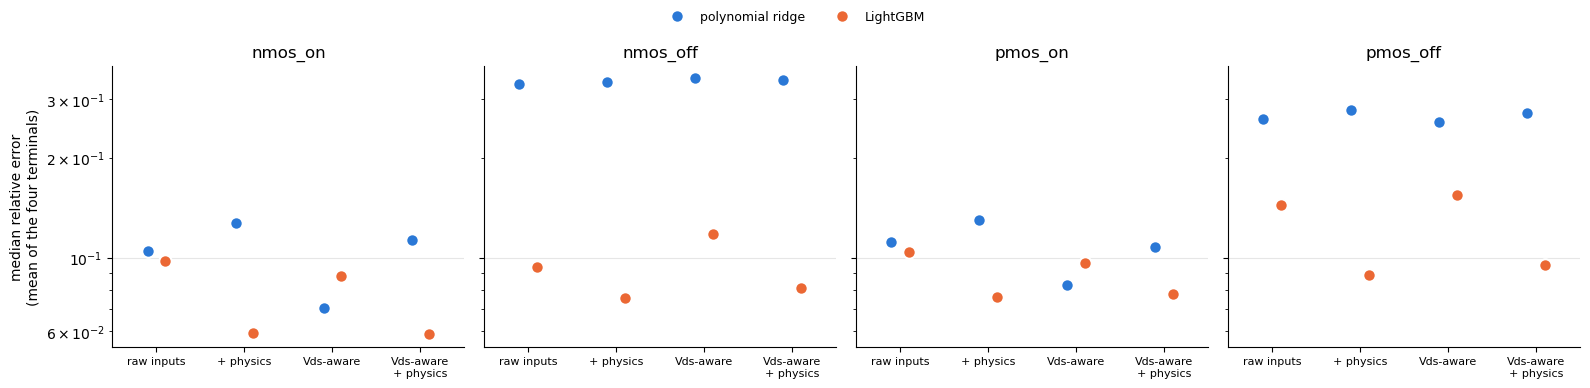

In [16]:
# effect of the two options: best median error of each family for each option set (log scale; lower is better)
COL = {"poly": "#2a78d6", "lightgbm": "#eb6834"}
LABEL = {"poly": "polynomial ridge", "lightgbm": "LightGBM"}
labels = ["raw inputs", "+ physics", "Vds-aware", "Vds-aware\n+ physics"]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.9), sharey=True)
for a, case in zip(ax, CASES):
    for fam, dx in (("poly", -0.1), ("lightgbm", 0.1)):
        vals = [baselines[(baselines.case == case) & (baselines.family == fam) & (baselines.vds_aware == aw) & (baselines.physics == ph)]["median_rel"].min()
                for aw, ph in OPTIONS]
        a.plot(np.arange(4) + dx, vals, "o", ms=9, color=COL[fam], mec="white", mew=1.5, label=LABEL[fam])
    a.set_yscale("log"); a.set_title(case); a.set_xticks(range(4)); a.set_xticklabels(labels, fontsize=8); a.set_xlim(-0.5, 3.5)
    a.grid(axis="y", color="0.9", lw=0.8); a.set_axisbelow(True)
    a.spines[["top", "right"]].set_visible(False)
ax[0].set_ylabel("median relative error\n(mean of the four terminals)")
handles, names = ax[0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper center", ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(RESULT_DIR / "baseline_options.png", dpi=110)
plt.show()

## Summary of the baselines
Validation rows only (median relative error, mean of the four terminals; the test rows have not been used):

| case | LightGBM | polynomial ridge |
|---|---|---|
| NMOS ON | 5.9 % | 7.1 % |
| NMOS OFF | 7.6 % | 33.4 % |
| PMOS ON | 7.6 % | 8.3 % |
| PMOS OFF | 8.9 % | 25.6 % |

* **Physics features** help LightGBM in every case (for example NMOS ON 9.8 % -> 5.9 %, PMOS OFF 14.4 % -> 8.9 %). They do not help polynomial ridge; the physics-feature polynomials are limited to degree 3 by the term cap, so that comparison is not like for like.
* **The Vds-aware target** helps the ON cases for polynomial ridge (NMOS ON 10.5 % -> 7.1 %, PMOS ON 11.1 % -> 8.3 %) and for LightGBM on the raw inputs (9.8 % -> 8.8 % and 10.4 % -> 9.7 %). It is neutral or slightly worse for LightGBM with the physics features, and it hurts both OFF cases for LightGBM (NMOS OFF 7.6 % -> 8.1 %, PMOS OFF 8.9 % -> 9.5 %). The OFF-case result fits the explanation in section 3 (the OFF-state `id` has Vds-independent components); the slopes there are too noisy to decide the ON cases, which the validation rows do.
* **Polynomials cannot follow the OFF currents**, which span many decades (33 % and 26 % median error, and 94 % and 43 % for `is`).
* For LightGBM the hardest terminal is `is` in the OFF cases (17.3 % NMOS OFF, 15.1 % PMOS OFF); in the ON cases it is `ib` (and `ig` in PMOS ON), about 10 %.
* No baseline is near the 1 % goal (best: 5.9 %), so the neural models of section 12 are needed.
* Several LightGBM terminals ended at or just below the 3,000-tree cap, so those fits are not fully converged; it was not tuned further because it is a baseline.
* In 9 of the 40 polynomial fits at least one terminal chose the smallest penalty of the grid (1e-6), i.e. an essentially unregularised fit.
* For 1 of the 8 family and case pairs (LightGBM, PMOS ON), picking by R2 of the signed-log currents instead of the median error would choose a different option set (column `same_choice_by_r2`); the selection rule stays the median error.

Next: the neural models and the full comparison (sections 11-13).

## 11. Resolution of the simulated currents
Before the neural models, a property of the data that matters for how the target is scaled: the simulator reports small currents only to a finite resolution. Many values are exact multiples of 2^-51 A = 4.4e-16 A (an observed property of the data; 4.4e-16 is the spacing of double-precision numbers between 2 and 4). A rounding to that grid costs a typical error of a quarter of a quantum, which is more than 1 % of the current below about 25 quanta = 1.1e-14 A.

In [17]:
QUANTUM = 2.0 ** -51                       # 4.44e-16 A
res = []
for c, d in data.items():
    for t in TERMS:
        x = np.abs(d[t].to_numpy())
        k = x / QUANTUM
        used = x >= REL_FLOOR
        res.append(dict(case=c, terminal=t, on_grid=float((np.abs(k - np.round(k)) < 1e-3).mean()),
                        below_25_quanta=float((x[used] < 25 * QUANTUM).mean())))
res = pd.DataFrame(res)
print("share of the values that are exact multiples of 2^-51 A, in % (a value picked at random passes this test with probability 0.2 %):")
display((res.pivot(index="case", columns="terminal", values="on_grid")[TERMS] * 100).round(1))
print("share of the rows used for the relative errors with |I| < 25 quanta = 1.1e-14 A, in % (rounding alone costs more than 1 % there; it applies to the terminals above that are on the grid):")
(res.pivot(index="case", columns="terminal", values="below_25_quanta")[TERMS] * 100).round(1)

share of the values that are exact multiples of 2^-51 A, in % (a value picked at random passes this test with probability 0.2 %):


terminal,id,ig,is,ib
case,,,,
nmos_off,0.2,0.2,0.2,3.9
nmos_on,0.2,43.6,0.2,0.2
pmos_off,0.1,43.1,0.2,15.0
pmos_on,0.2,0.2,0.2,6.4


share of the rows used for the relative errors with |I| < 25 quanta = 1.1e-14 A, in % (rounding alone costs more than 1 % there; it applies to the terminals above that are on the grid):


terminal,id,ig,is,ib
case,,,,
nmos_off,0.0,0.0,0.0,27.2
nmos_on,0.0,0.1,0.0,5.9
pmos_off,17.9,63.9,17.7,26.6
pmos_on,0.0,8.7,0.0,7.4


## 12. Neural models
Two network types, both predicting the four standardised targets at once from the 20 standardised physics features:
* **Plain MLP:** 3 hidden layers of 256 units, SiLU activations.
* **Residual MLP (ResNN):** an input layer of 128 units, 4 residual blocks `h <- SiLU(h + Linear(SiLU(Linear(h))))` and a linear output layer.

Training: AdamW (weight decay 1e-5), batch size 256, one-cycle learning rate with a peak of 3e-3, 600 epochs, seed `MODEL_SEED`. After every epoch the validation MSE is computed and the **epoch with the lowest validation MSE is kept** (so, as for LightGBM, the validation errors are slightly optimistic; the test rows give the unbiased numbers in part 4). Two loss functions are compared per case: **MSE** and **Huber** (smooth L1 with a 0.05 transition on the standardised targets, which is closer to the median error that is used for selection).
The physics features are used for both networks (they helped every baseline case in section 10).
Networks are trained in parallel worker processes (4 processes with 3 threads each), one network per process.

In [18]:
import copy

import torch
import torch.nn as nn
from joblib import Parallel, delayed


class PlainMLP(nn.Module):
    """`depth` hidden layers of `width` units with SiLU activations."""

    def __init__(self, d_in, d_out, width=256, depth=3):
        super().__init__()
        layers, d = [], d_in
        for _ in range(depth):
            layers += [nn.Linear(d, width), nn.SiLU()]
            d = width
        layers.append(nn.Linear(d, d_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class ResidualMLP(nn.Module):
    """Input layer, residual blocks h <- SiLU(h + Linear(SiLU(Linear(h)))), linear output layer."""

    def __init__(self, d_in, d_out, width=128, blocks=4):
        super().__init__()
        self.inp = nn.Linear(d_in, width)
        self.blocks = nn.ModuleList([nn.Sequential(nn.Linear(width, width), nn.SiLU(), nn.Linear(width, width)) for _ in range(blocks)])
        self.act = nn.SiLU()
        self.out = nn.Linear(width, d_out)

    def forward(self, x):
        h = self.act(self.inp(x))
        for block in self.blocks:
            h = self.act(h + block(h))
        return self.out(h)


class TorchModel:
    """MLP ("mlp") or residual MLP ("resnn") with AdamW and a one-cycle schedule; the epoch with the lowest validation MSE is kept."""

    def __init__(self, kind, loss="mse", epochs=600, lr=3e-3, batch=256, weight_decay=1e-5, threads=3):
        self.kind, self.loss, self.epochs, self.lr, self.batch, self.weight_decay, self.threads = kind, loss, epochs, lr, batch, weight_decay, threads

    def fit(self, X, Y, X_val, Y_val):
        torch.set_num_threads(self.threads)
        torch.manual_seed(MODEL_SEED)
        Xt, Yt = torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)
        Xv, Yv = torch.tensor(X_val, dtype=torch.float32), torch.tensor(Y_val, dtype=torch.float32)
        net = PlainMLP(Xt.shape[1], Yt.shape[1]) if self.kind == "mlp" else ResidualMLP(Xt.shape[1], Yt.shape[1])
        opt = torch.optim.AdamW(net.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        steps = int(np.ceil(len(Xt) / self.batch))
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=self.lr, total_steps=self.epochs * steps, pct_start=0.1, final_div_factor=1e3)
        loss_fn = nn.MSELoss() if self.loss == "mse" else nn.SmoothL1Loss(beta=0.05)
        best_mse, best_state, best_epoch = np.inf, None, 0
        for epoch in range(self.epochs):
            net.train()
            perm = torch.randperm(len(Xt))
            for i in range(0, len(Xt), self.batch):
                idx = perm[i:i + self.batch]
                opt.zero_grad()
                loss_fn(net(Xt[idx]), Yt[idx]).backward()
                opt.step()
                sched.step()
            net.eval()
            with torch.no_grad():
                mse = float(((net(Xv) - Yv) ** 2).mean())
            if mse < best_mse:
                best_mse, best_state, best_epoch = mse, copy.deepcopy(net.state_dict()), epoch + 1
        net.load_state_dict(best_state)
        net.eval()
        self.net = net
        self.setting = f"{self.kind}, {self.loss} loss, {self.epochs} epochs (best epoch {best_epoch})"
        return self

    def predict(self, X):
        with torch.no_grad():
            return self.net(torch.tensor(X, dtype=torch.float32)).numpy()


def fit_job(model, prep):
    return model.fit(prep["X"][prep["tr"]], prep["Y"][prep["tr"]], prep["X"][prep["va"]], prep["Y"][prep["va"]])


def fit_all(jobs, n_jobs=4):
    """jobs: list of (model, prep); trained in parallel worker processes; returns the fitted models in the same order."""
    t0, out = time.time(), []
    for k, model in enumerate(Parallel(n_jobs=n_jobs, return_as="generator")(delayed(fit_job)(m, p) for m, p in jobs)):
        out.append(model)
        print(f"  {k + 1}/{len(jobs)} trained after {time.time() - t0:.0f} s")
    return out


# repeatability: the same training twice must give identical predictions
prep = prep_cache[("nmos_on", True, True)]
twice = [TorchModel("resnn", epochs=5).fit(prep["X"][prep["tr"]], prep["Y"][prep["tr"]], prep["X"][prep["va"]], prep["Y"][prep["va"]]).predict(prep["X"][prep["va"]]) for _ in range(2)]
print("two identical trainings give identical predictions:", bool(np.array_equal(*twice)))

two identical trainings give identical predictions: True


### 12.1 Choice of the target scale I0
`I0` of the signed-log target `arcsinh(I / I0)` is the current below which the target is linear (absolute errors) and above which it is logarithmic (relative errors). With a small `I0` the loss spends effort on the rounding steps of section 11. The residual MLP is trained for 300 epochs with MSE loss on each case for four values of `I0`; all other settings are fixed (physics features, no Vds-aware factor). The median error is in the original currents, so the values are comparable across `I0`.

In [19]:
I0_VALUES = [1e-16, 1e-15, 1e-14, 1e-13]
study_prep = {(c, i0): prepare(c, False, True, i0=i0) for c in CASES for i0 in I0_VALUES}
keys = list(study_prep)
study_models = fit_all([(TorchModel("resnn", epochs=300), study_prep[k]) for k in keys])
study = []
for k, model in zip(keys, study_models):
    r = evaluate(model, study_prep[k], "resnn")
    study.append(dict(case=k[0], i0=k[1], median_rel=r["median_rel"], p95_rel=r["p95_rel"]))
study = pd.DataFrame(study)
study.to_csv(RESULT_DIR / "i0_study.csv", index=False)
print("median relative error (mean of the four terminals) on the validation rows:")
display(study.pivot(index="case", columns="i0", values="median_rel").round(4))
print("95th-percentile relative error:")
study.pivot(index="case", columns="i0", values="p95_rel").round(3)

  1/16 trained after 552 s


  2/16 trained after 553 s
  3/16 trained after 553 s
  4/16 trained after 553 s


  5/16 trained after 1114 s
  6/16 trained after 1114 s


  7/16 trained after 1115 s
  8/16 trained after 1115 s


  9/16 trained after 1315 s


  10/16 trained after 1316 s


... (4 outputs left out)

median relative error (mean of the four terminals) on the validation rows:


i0,1.000000e-16,1.000000e-15,1.000000e-14,1.000000e-13
case,,,,
nmos_off,0.0160,0.0136,0.0118,0.0103
nmos_on,0.0149,0.0136,0.0132,0.0128
pmos_off,0.1129,0.0355,0.0200,0.0194
pmos_on,0.0114,0.0104,0.0112,0.0119


95th-percentile relative error:


i0,1.000000e-16,1.000000e-15,1.000000e-14,1.000000e-13
case,,,,
nmos_off,0.092,0.081,0.072,0.097
nmos_on,0.088,0.082,0.080,0.095
pmos_off,0.397,0.150,0.118,0.249
pmos_on,0.055,0.052,0.054,0.107


### 12.2 Plain MLP and residual MLP on every case
For each case, both networks are trained with both losses and with and without the Vds-aware target (physics features throughout): 32 networks at 600 epochs. As for the baselines, the best setting of each network type and case is chosen by the validation median error.

In [20]:
grid = [(case, kind, aware, loss) for case in CASES for kind in ("mlp", "resnn") for aware in (False, True) for loss in ("mse", "huber")]
nn_models = fit_all([(TorchModel(kind, loss), prep_cache[(case, aware, True)]) for case, kind, aware, loss in grid])
for (case, kind, aware, loss), model in zip(grid, nn_models):
    register(kind, prep_cache[(case, aware, True)], model)
results = pd.DataFrame(rows)
nets = results[results.family.isin(["mlp", "resnn"])].copy()
nets["loss"] = nets.setting.str.extract(r", (\w+) loss")[0]
print("median relative error (mean of the four terminals) on the validation rows, by case, network, Vds-aware target and loss:")
nets.pivot_table(index=["case", "family"], columns=["vds_aware", "loss"], values="median_rel").round(4)

  1/32 trained after 250 s


  2/32 trained after 251 s
  3/32 trained after 251 s
  4/32 trained after 251 s


  5/32 trained after 671 s
  6/32 trained after 671 s


  7/32 trained after 693 s
  8/32 trained after 693 s


  9/32 trained after 950 s


  10/32 trained after 951 s


... (16 outputs left out)

  31/32 trained after 2734 s


  32/32 trained after 2749 s


median relative error (mean of the four terminals) on the validation rows, by case, network, Vds-aware target and loss:


vds_aware         False           True         
loss              huber     mse   huber     mse
case     family                                
nmos_off mlp     0.0103  0.0086  0.0133  0.0144
         resnn   0.0101  0.0059  0.0066  0.0082
nmos_on  mlp     0.0071  0.0083  0.0054  0.0071
         resnn   0.0051  0.0065  0.0039  0.0053
pmos_off mlp     0.0177  0.0197  0.0173  0.0167
         resnn   0.0133  0.0139  0.0135  0.0124
pmos_on  mlp     0.0073  0.0079  0.0036  0.0044
         resnn   0.0050  0.0059  0.0024  0.0040

## 13. Model comparison (deliverable 4)
Four model types for each case, each with its best option set and settings chosen on the validation rows. The table gives R2 (of the signed-log currents), the median error and the 95th-percentile error, each the mean over the four terminals, as defined in section 5.

In [21]:
FAMILIES = ["poly", "lightgbm", "mlp", "resnn"]
NAMES = {"poly": "polynomial ridge", "lightgbm": "LightGBM", "mlp": "MLP", "resnn": "residual MLP"}
results = pd.DataFrame(rows)
results.to_csv(RESULT_DIR / "model_comparison_all_runs.csv", index=False)
pick = results.loc[results.groupby(["case", "family"])["median_rel"].idxmin()].set_index(["case", "family"])
table4 = pd.DataFrame({(NAMES[f], name): pick.xs(f, level="family")[col] * scale for f in FAMILIES
                       for name, col, scale in (("R2", "r2_log", 1), ("median error [%]", "median_rel", 100), ("95th pct error [%]", "p95_rel", 100))}).loc[list(CASES)]
table4.to_csv(RESULT_DIR / "model_comparison_table.csv")
display(table4.round({c: 4 if c[1] == "R2" else 2 for c in table4.columns}))
winner = pick.groupby("case")["median_rel"].idxmin().map(lambda k: k[1])
print("best model type per case on the validation rows:", {c: NAMES[f] for c, f in winner.items()})

polynomial ridge                                     LightGBM                                         MLP                                     residual MLP                   \
                       R2 median error [%] 95th pct error [%]       R2 median error [%] 95th pct error [%]      R2 median error [%] 95th pct error [%]           R2 median error [%]   
case                                                                                                                                                                                   
nmos_on            0.9980             7.06              27.73   0.9983             5.90              27.75  1.0000             0.54               3.25       1.0000             0.39   
nmos_off           0.9736            33.43             268.92   0.9941             7.56              39.61  0.9987             0.86               8.59       0.9995             0.59   
pmos_on            0.9983             8.26              31.11   0.9981             7.62              31.91  1.0000             0.36               1.90       1.0000             0.24   
pmos_off           0.9875            25.58             175.78   0.9975             8.87              38.46  0.9995             1.67              14.18       0.9996             1.24   

                             
         95th pct error [%]  
case                         
nmos_on                2.17  
nmos_off               4.13  
pmos_on                1.24  
pmos_off               9.85

best model type per case on the validation rows: {'nmos_off': 'residual MLP', 'nmos_on': 'residual MLP', 'pmos_off': 'residual MLP', 'pmos_on': 'residual MLP'}


In [22]:
# per-terminal detail of the best setting of every model type and case
detail = pick[["vds_aware", "physics", "median_rel", "median_rel_id", "median_rel_ig", "median_rel_is", "median_rel_ib", "p95_rel", "r2_log", "setting"]]
detail.round({"median_rel": 4, "median_rel_id": 4, "median_rel_ig": 4, "median_rel_is": 4, "median_rel_ib": 4, "p95_rel": 3, "r2_log": 5})

vds_aware  physics  median_rel  median_rel_id  median_rel_ig  median_rel_is  median_rel_ib  p95_rel   r2_log                                         setting
case     family                                                                                                                                                                
nmos_off lightgbm      False     True      0.0756         0.0607         0.0396         0.1729         0.0290    0.396  0.99410                   trees=[2995, 2460, 383, 1884]
         mlp           False     True      0.0086         0.0045         0.0032         0.0182         0.0086    0.086  0.99875      mlp, mse loss, 600 epochs (best epoch 536)
         poly          False    False      0.3343         0.1716         0.0210         0.9362         0.2085    2.689  0.97357      degree=4, alpha=[3.16, 1e-06, 3.16, 0.316]
         resnn         False     True      0.0059         0.0037         0.0028         0.0106         0.0065    0.041  0.99949    resnn, mse loss, 600 epochs (best epoch 575)
nmos_on  lightgbm       True     True      0.0590         0.0402         0.0579         0.0388         0.0991    0.278  0.99825                  trees=[1611, 3000, 2967, 2995]
         mlp            True     True      0.0054         0.0059         0.0046         0.0060         0.0051    0.032  0.99996    mlp, huber loss, 600 epochs (best epoch 582)
         poly           True    False      0.0706         0.0680         0.0502         0.0667         0.0974    0.277  0.99799    degree=4, alpha=[0.316, 0.316, 0.316, 0.316]
         resnn          True     True      0.0039         0.0044         0.0035         0.0039         0.0038    0.022  0.99998  resnn, huber loss, 600 epochs (best epoch 538)
pmos_off lightgbm      False     True      0.0887         0.1176         0.0562         0.1510         0.0300    0.385  0.99750                   trees=[2991, 1272, 1807, 592]
         mlp            True     True      0.0167         0.0173         0.0130         0.0239         0.0127    0.142  0.99946      mlp, mse loss, 600 epochs (best epoch 489)
         poly           True    False      0.2558         0.3009         0.0675         0.4307         0.2240    1.758  0.98749           degree=4, alpha=[1.0, 1.0, 3.16, 1.0]
         resnn          True     True      0.0124         0.0128         0.0119         0.0162         0.0086    0.099  0.99961    resnn, mse loss, 600 epochs (best epoch 553)
pmos_on  lightgbm      False     True      0.0762         0.0449         0.1077         0.0448         0.1075    0.319  0.99809                  trees=[2761, 2987, 2980, 2999]
         mlp            True     True      0.0036         0.0033         0.0034         0.0038         0.0039    0.019  0.99999    mlp, huber loss, 600 epochs (best epoch 593)
         poly           True    False      0.0826         0.0657         0.0909         0.0763         0.0976    0.311  0.99831    degree=4, alpha=[1e-06, 0.316, 0.316, 0.316]
         resnn          True     True      0.0024         0.0027         0.0021         0.0026         0.0023    0.012  1.00000  resnn, huber loss, 600 epochs (best epoch 598)

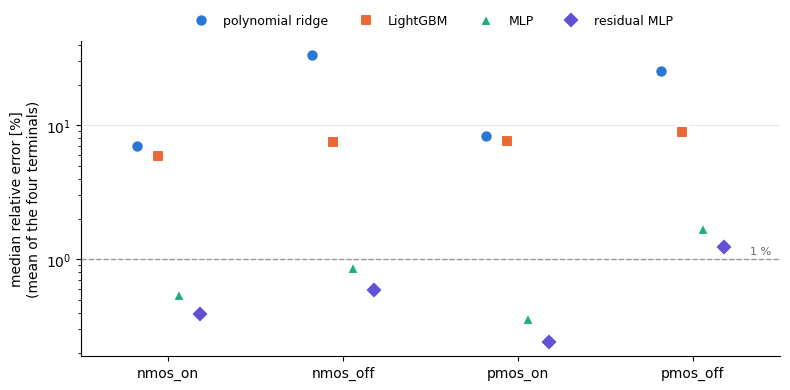

In [23]:
# best median error of each model type and case (log scale; lower is better)
COL = {"poly": "#2a78d6", "lightgbm": "#eb6834", "mlp": "#1baf7a", "resnn": "#6250d6"}
MARK = {"poly": "o", "lightgbm": "s", "mlp": "^", "resnn": "D"}
fig, ax = plt.subplots(figsize=(8, 4))
for j, f in enumerate(FAMILIES):
    ax.plot(np.arange(4) + (j - 1.5) * 0.12, [pick.loc[(c, f), "median_rel"] * 100 for c in CASES], MARK[f], ms=9, color=COL[f], mec="white", mew=1.5, label=NAMES[f])
ax.set_yscale("log"); ax.set_xticks(range(4)); ax.set_xticklabels(list(CASES)); ax.set_xlim(-0.5, 3.5)
ax.set_ylabel("median relative error [%]\n(mean of the four terminals)")
ax.axhline(1.0, color="0.6", lw=1, ls="--"); ax.text(3.45, 1.05, "1 %", ha="right", va="bottom", color="0.4", fontsize=8)
ax.grid(axis="y", color="0.9", lw=0.8); ax.set_axisbelow(True); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.12), fontsize=9)
fig.tight_layout()
fig.savefig(RESULT_DIR / "model_comparison.png", dpi=110)
plt.show()

## Summary of the comparison
Validation rows only (median relative error in %, mean of the four terminals; the test rows have not been used):

| case | polynomial ridge | LightGBM | MLP | residual MLP |
|---|---|---|---|---|
| NMOS ON | 7.06 | 5.90 | 0.54 | **0.39** |
| NMOS OFF | 33.43 | 7.56 | 0.86 | **0.59** |
| PMOS ON | 8.26 | 7.62 | 0.36 | **0.24** |
| PMOS OFF | 25.58 | 8.87 | 1.67 | **1.24** |

The 95th-percentile error of the residual MLP is 2.2 % (NMOS ON), 4.1 % (NMOS OFF), 1.2 % (PMOS ON) and 9.9 % (PMOS OFF).

* **The residual MLP is the best model type in all four cases** and the plain MLP is second. Both networks are far more accurate than the two baselines; the residual MLP's median error is 7 to 32 times lower than the best baseline's.
* **Target scale `I0`:** with `I0 = 1e-16 A` the PMOS OFF median error of the residual MLP is 11.3 %; it falls to 3.6 % at 1e-15 and 2.0 % at 1e-14 (section 12.1). NMOS OFF goes from 1.6 % to 1.2 %, and the two ON cases change by less than 0.2 percentage points. `I0 = 1e-13` lowers the OFF medians a little more but raises the 95th percentile (NMOS OFF 7.2 % -> 9.7 %, PMOS OFF 11.8 % -> 24.9 %) and the PMOS ON median, so `1e-14` is used.
* **Vds-aware target:** it lowers the residual MLP error in the ON cases (NMOS ON 0.51 % -> 0.39 %, PMOS ON 0.50 % -> 0.24 %), does not help NMOS OFF (0.59 % without, 0.66 % with) and changes PMOS OFF only slightly (1.33 % -> 1.24 %).
* **Loss:** Huber is better in every ON-case run. In the OFF cases the two losses are close and neither wins every run, but the best setting of each network type uses MSE.
* **PMOS OFF is the least accurate case.** Its terminals are the smallest currents, and the resolution of the data (section 11) bounds what any model can reach there: 64 % of its `ig` rows that enter the error lie below 1.1e-14 A.
* The best epoch is at the end of training for most networks (for example epoch 598 of 600), so longer training may still help.
* The validation errors of all four model types are slightly optimistic, because the option set and the number of trees or epochs were chosen on the same rows. Part 4 selects the final model per case and reports the test rows once.

## 14. Final model per case and test-set results (deliverable 5)
**Selection (validation rows only):** for every case, the model type with the lowest validation median error (section 13), with the option set and settings that were chosen for it. The four chosen models are fitted on the training rows only; no model is refitted on training + validation rows.

**Test rows:** scored once, for these four models only. The test rows have played no part in any choice: the split, scalers, target scale, option sets, number of epochs or trees and the final model were all fixed on training and validation rows. The table gives, per terminal and as the mean over the four terminals, the median and 95th-percentile relative error (rows with `|I| >= 1e-15 A`), the **mean** relative error (the project text speaks of "mean accuracy", so it is reported too) and R2 of the signed-log currents. The validation value of the same model is listed next to it, to show how optimistic the validation numbers were.

In [24]:
chosen = {case: best[(case, winner[case])] for case in CASES}          # (validation median error, fitted model, (vds_aware, physics))
print({case: (NAMES[winner[case]], f"vds_aware={chosen[case][2][0]}", chosen[case][1].setting) for case in CASES})
assert all(winner[case] in ("mlp", "resnn") for case in CASES), "the saving code below handles the neural models only"


def test_report(model, prep):
    """Per-terminal test-set metrics of a fitted model: score() of section 5 plus the mean relative error."""
    te = prep["te"]
    true, pred = prep["cur"][te], to_currents(model.predict(prep["X"][te]), prep, te)
    s = score(true, pred, prep["vds"][te], prep["i0"])
    for k, t in enumerate(TERMS):
        m = np.abs(true[:, k]) >= REL_FLOOR
        s.loc[t, "mean_rel"] = np.mean(np.abs(pred[m, k] - true[m, k]) / np.abs(true[m, k]))
    return s, true, pred


test, test_true, test_pred = {}, {}, {}
for case in CASES:
    prep = prep_cache[(case, *chosen[case][2])]
    test[case], test_true[case], test_pred[case] = test_report(chosen[case][1], prep)

summary = pd.DataFrame({case: dict(model=NAMES[winner[case]],
                                   val_median=chosen[case][0] * 100,
                                   test_median=test[case]["median_rel"].mean() * 100,
                                   test_p95=test[case]["p95_rel"].mean() * 100,
                                   test_mean=test[case]["mean_rel"].mean() * 100,
                                   test_r2_log=test[case]["r2_log"].mean(),
                                   test_r2_lin=test[case]["r2_lin"].mean()) for case in CASES}).T
per_terminal = pd.concat({case: test[case][["median_rel", "p95_rel", "mean_rel", "r2_log", "r2_lin", "median_rel_small_vds", "n_small_vds", "n_used", "frac_below_floor"]]
                          for case in CASES}, names=["case"])
summary.to_csv(RESULT_DIR / "chosen_models_test.csv")
per_terminal.to_csv(RESULT_DIR / "chosen_models_test_per_terminal.csv")
print("test rows (1,500 per case); errors in %, each the mean over the four terminals; the validation median of the same model is shown for comparison:")
display(summary.astype({c: float for c in summary.columns if c != "model"}).round({"val_median": 2, "test_median": 2, "test_p95": 2, "test_mean": 2, "test_r2_log": 4, "test_r2_lin": 4}))

{'nmos_on': ('residual MLP', 'vds_aware=True', 'resnn, huber loss, 600 epochs (best epoch 538)'), 'nmos_off': ('residual MLP', 'vds_aware=False', 'resnn, mse loss, 600 epochs (best epoch 575)'), 'pmos_on': ('residual MLP', 'vds_aware=True', 'resnn, huber loss, 600 epochs (best epoch 598)'), 'pmos_off': ('residual MLP', 'vds_aware=True', 'resnn, mse loss, 600 epochs (best epoch 553)')}
test rows (1,500 per case); errors in %, each the mean over the four terminals; the validation median of the same model is shown for comparison:


,model,val_median,test_median,test_p95,test_mean,test_r2_log,test_r2_lin
nmos_on,residual MLP,0.39,0.37,2.19,0.73,1.0000,0.9997
nmos_off,residual MLP,0.59,0.60,3.84,1.64,0.9995,0.9992
pmos_on,residual MLP,0.24,0.26,1.31,0.45,1.0000,0.9999
pmos_off,residual MLP,1.24,1.21,9.31,3.05,0.9997,0.9992


In [25]:
print("per terminal, test rows (errors in %):")
pt = per_terminal.copy()
for c in ("median_rel", "p95_rel", "mean_rel", "median_rel_small_vds", "frac_below_floor"):
    pt[c] = pt[c] * 100
pt.round({"median_rel": 2, "p95_rel": 2, "mean_rel": 2, "r2_log": 4, "r2_lin": 4, "median_rel_small_vds": 2, "frac_below_floor": 1})

per terminal, test rows (errors in %):


median_rel  p95_rel  mean_rel  r2_log  r2_lin  median_rel_small_vds  n_small_vds  n_used  frac_below_floor
case     terminal                                                                                                            
nmos_on  id              0.40     2.47      0.83  1.0000  1.0000                  1.22           20    1500               0.0
         ig              0.36     1.97      0.65  1.0000  0.9997                  0.72           20    1500               0.0
         is              0.37     2.20      0.76  1.0000  1.0000                  0.93           20    1500               0.0
         ib              0.36     2.10      0.69  1.0000  0.9992                  0.61           20    1490               0.7
nmos_off id              0.40     2.29      0.92  0.9998  0.9998                  0.75           19    1500               0.0
         ig              0.31     1.37      0.48  1.0000  0.9999                  0.65           19    1500               0.0
         is              1.00     8.38      4.05  0.9981  0.9973                  1.52           19    1500               0.0
         ib              0.67     3.32      1.11  1.0000  0.9999                  1.04           10     611              59.3
pmos_on  id              0.28     1.25      0.43  1.0000  1.0000                  0.85           23    1499               0.1
         ig              0.23     1.28      0.51  1.0000  0.9999                  0.55           23    1480               1.3
         is              0.28     1.16      0.42  1.0000  1.0000                  0.56           23    1499               0.1
         ib              0.23     1.55      0.46  1.0000  0.9999                  0.58           23    1480               1.3
pmos_off id              1.28     7.65      2.61  0.9998  0.9980                 14.90           18    1391               7.3
         ig              1.18    13.05      3.51  0.9995  0.9999                  0.81           11     907              39.5
         is              1.60    11.75      4.57  0.9996  0.9994                 18.35           17    1306              12.9
         ib              0.78     4.81      1.49  0.9999  0.9997                  4.43           12     645              57.0

### Predicted against SPICE
One figure per case, one panel per terminal (1,500 test rows). Both axes are symmetric-log (linear below `I0 = 1e-14 A`, logarithmic above, with the sign kept); the dashed line is the identity. The title of each panel gives the median relative error of that terminal.

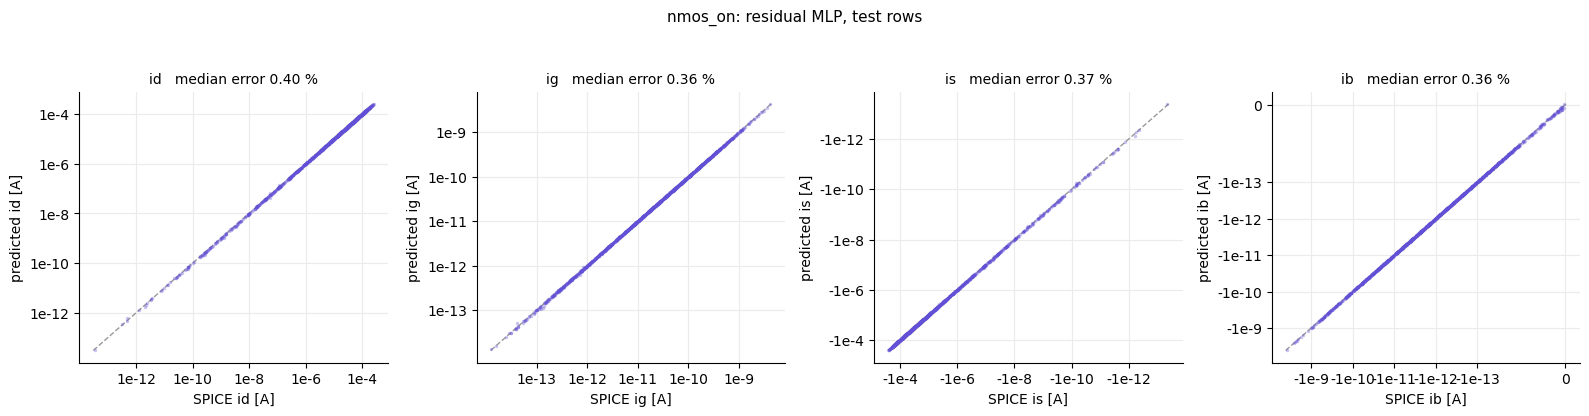

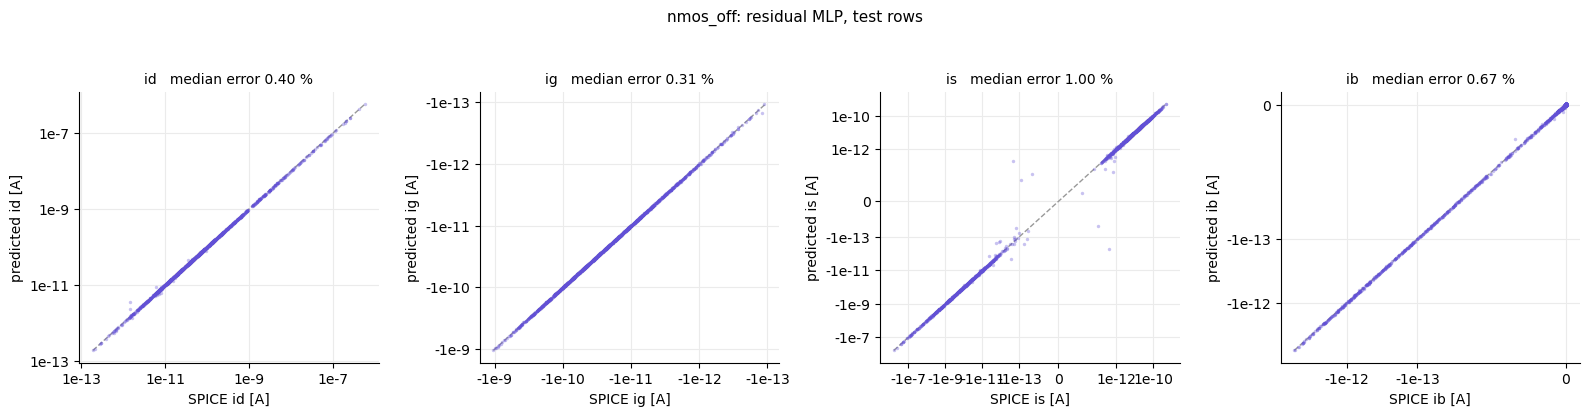

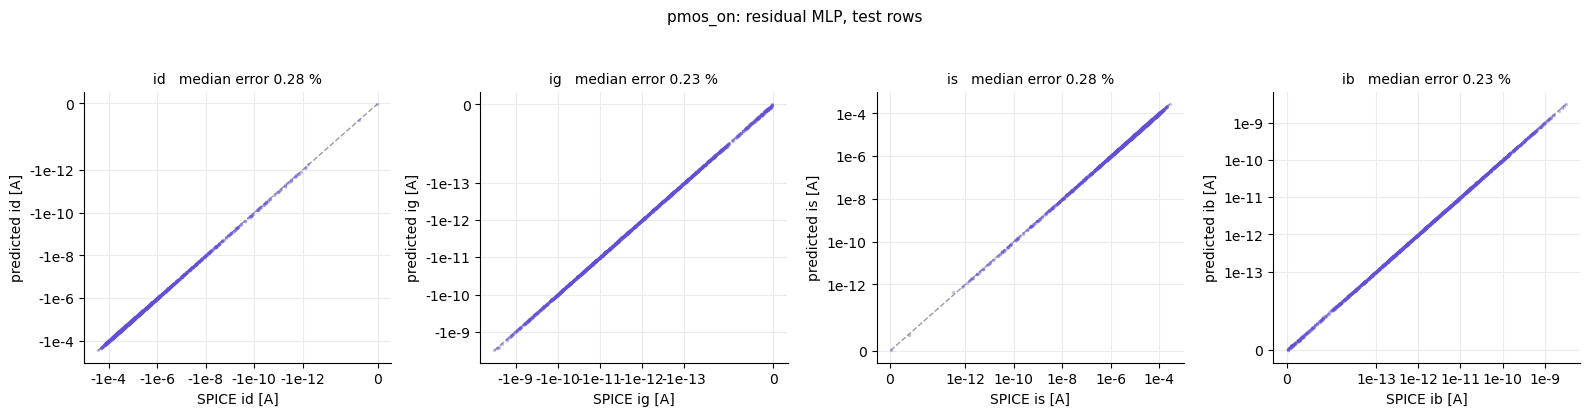

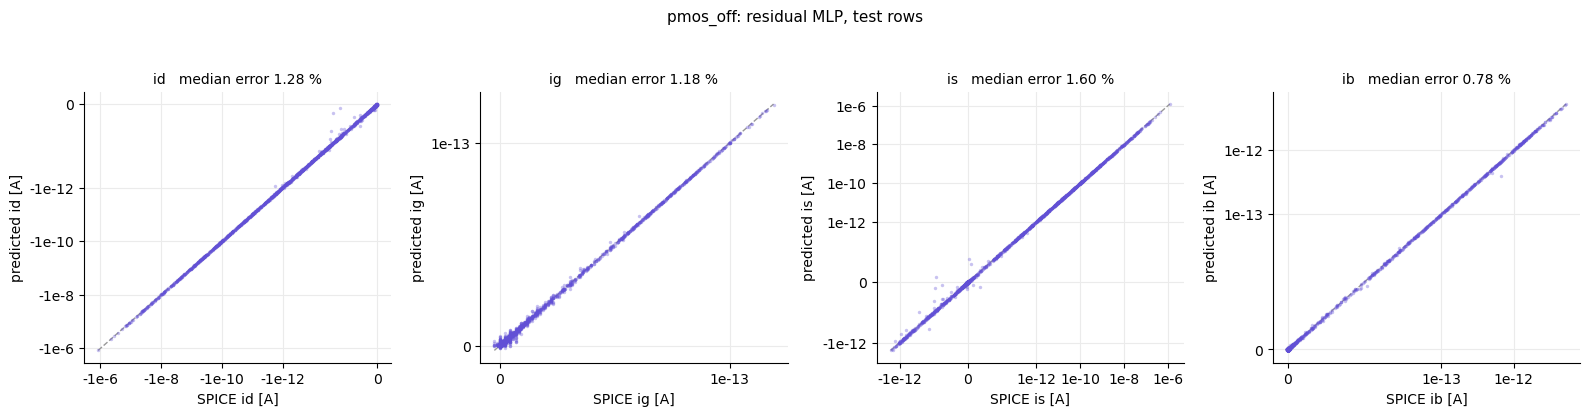

In [26]:
from matplotlib.ticker import FuncFormatter


def sym_ticks(lo, hi, max_ticks=6):
    """Tick positions for a symmetric-log axis: powers of ten above I0 on either side of zero, thinned to about max_ticks (and zero)."""
    k0 = int(np.log10(I0)) + 1                       # the decade at I0 itself is left out: it would sit on top of the label 0
    pos = [10.0 ** k for k in range(k0, int(np.floor(np.log10(hi))) + 1)] if hi > I0 else []
    neg = [-10.0 ** k for k in range(int(np.floor(np.log10(-lo))), k0 - 1, -1)] if lo < -I0 else []
    step = int(np.ceil((len(pos) + len(neg) + 1) / max_ticks))
    return neg[::step] + [0.0] + pos[::-1][::step][::-1]


def pred_vs_spice(case):
    true, pred = test_true[case], test_pred[case]
    fig, ax = plt.subplots(1, 4, figsize=(16, 4.2))
    for k, (a, t) in enumerate(zip(ax, TERMS)):
        lo, hi = min(true[:, k].min(), pred[:, k].min()), max(true[:, k].max(), pred[:, k].max())
        a.set_xscale("symlog", linthresh=I0); a.set_yscale("symlog", linthresh=I0)
        a.set_xticks(sym_ticks(lo, hi)); a.set_yticks(sym_ticks(lo, hi))
        a.xaxis.set_minor_locator(plt.NullLocator()); a.yaxis.set_minor_locator(plt.NullLocator())
        a.xaxis.set_major_formatter(FuncFormatter(lambda v, _: "0" if v == 0 else f"{v:.0e}".replace("e-0", "e-").replace("e+0", "e")))
        a.yaxis.set_major_formatter(a.xaxis.get_major_formatter())
        a.plot([lo, hi], [lo, hi], color="0.6", lw=1, ls="--", zorder=1)
        a.scatter(true[:, k], pred[:, k], s=6, alpha=0.35, color=COL["resnn"] if winner[case] == "resnn" else COL["mlp"], linewidths=0, zorder=2)
        a.set_title(f"{t}   median error {test[case].loc[t, 'median_rel'] * 100:.2f} %", fontsize=10)
        a.set_xlabel(f"SPICE {t} [A]"); a.set_ylabel(f"predicted {t} [A]")
        a.grid(color="0.92", lw=0.8); a.set_axisbelow(True); a.spines[["top", "right"]].set_visible(False)
    fig.suptitle(f"{case}: {NAMES[winner[case]]}, test rows", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.savefig(RESULT_DIR / f"pred_vs_spice_{case}.png", dpi=110)
    plt.show()


for case in CASES:
    pred_vs_spice(case)

### Where the errors are
The relative error against the size of the current (test rows, rows with `|I| >= 1e-15 A`), per case and terminal, shown as the median and 95th percentile in decades of `|I|`. Small currents are the hard ones: they are close to the resolution of the data (section 11) and sum several components of opposite sign.

In [27]:
edges = np.array([1e-15, 1e-14, 1e-13, 1e-12, 1e-11, 1e-10, 1e-9, 1e-8, 1e-7, 1.0])
names_bins = ["1e-15..1e-14", "1e-14..1e-13", "1e-13..1e-12", "1e-12..1e-11", "1e-11..1e-10", "1e-10..1e-9", "1e-9..1e-8", "1e-8..1e-7", ">1e-7"]
tab = []
for case in CASES:
    true, pred = test_true[case], test_pred[case]
    for k, t in enumerate(TERMS):
        a = np.abs(true[:, k]); m = a >= REL_FLOOR
        rel = np.abs(pred[:, k] - true[:, k]) / np.where(a > 0, a, np.nan)
        which = np.digitize(a, edges) - 1
        for b, nm in enumerate(names_bins):
            sel = m & (which == b)
            if sel.sum() >= 10:
                tab.append(dict(case=case, terminal=t, bin=nm, n=int(sel.sum()), median=np.median(rel[sel]) * 100, p95=np.percentile(rel[sel], 95) * 100))
bins = pd.DataFrame(tab)
bins.to_csv(RESULT_DIR / "chosen_models_test_by_size.csv", index=False)
print("median relative error [%] on the test rows by |I| bin (bins with at least 10 rows):")
bins.pivot_table(index=["case", "terminal"], columns="bin", values="median")[[b for b in names_bins if b in set(bins["bin"])]].round(2)

median relative error [%] on the test rows by |I| bin (bins with at least 10 rows):


bin                1e-15..1e-14  1e-14..1e-13  1e-13..1e-12  1e-12..1e-11  1e-11..1e-10  1e-10..1e-9  1e-9..1e-8  1e-8..1e-7  >1e-7
case     terminal                                                                                                                  
nmos_off ib                1.12          0.52          0.55          0.53           NaN          NaN         NaN         NaN    NaN
         id                 NaN           NaN          0.68          0.48          0.34         0.41        0.47        0.62   1.28
         ig                 NaN           NaN          0.69          0.44          0.27         0.28         NaN         NaN    NaN
         is                 NaN           NaN          3.51          1.09          0.76         0.87        1.19        1.55   2.50
nmos_on  ib                2.26          0.68          0.39          0.31          0.25         0.30        0.80         NaN    NaN
         id                 NaN           NaN           NaN          2.65          1.77         1.76        1.26        1.09   0.35
         ig                 NaN          1.78          1.03          0.49          0.26         0.29        0.32         NaN    NaN
         is                 NaN           NaN           NaN           NaN          2.49         1.30        1.04        0.94   0.33
pmos_off ib                2.02          0.72          0.63          0.53           NaN          NaN         NaN         NaN    NaN
         id                2.05          1.57          1.89          1.23          0.78         0.70        1.02        1.06   1.51
         ig                2.50          0.41          0.43           NaN           NaN          NaN         NaN         NaN    NaN
         is                3.46          3.17          2.29          1.24          0.75         0.77        0.87        1.00   1.11
pmos_on  ib                1.56          0.41          0.29          0.19          0.15         0.18        0.30         NaN    NaN
         id                 NaN           NaN           NaN          0.95          0.41         0.47        0.49        0.48   0.26
         ig                1.12          0.31          0.25          0.15          0.15         0.19        0.35         NaN    NaN
         is                 NaN           NaN           NaN          1.21          0.45         0.52        0.42        0.44   0.25

## 15. The four saved model files
Each chosen model is written to `models/<case>.npz`: the network weights, the input and output scalers and the settings of the target transform, as plain arrays and one JSON string. No pickle and no PyTorch are needed to use it.

`SavedModel` is the callable used from here on: it takes a table with the **12 raw input columns** (`vdd, temp, w, vd, vs, vg, vb, vth0, toxe, ndep, u0, xj`) in any orientation of drain and source and returns the four terminal currents `id, ig, is, ib` (A, into the device) in that same orientation. Inside it does the same steps as training: swap drain and source if needed, build the features, standardise, run the network (a NumPy forward pass), invert the target transform and swap `id` and `is` back.

In [28]:
import json


def export_model(case, path):
    model, (aware, physics) = chosen[case][1], chosen[case][2]
    prep = prep_cache[(case, aware, physics)]
    meta = dict(case=case, device=CASES[case], kind=winner[case], vds_aware=bool(aware), physics=bool(physics), i0=float(prep["i0"]),
                columns=prep["columns"], feats=FEATS, terms=TERMS, setting=model.setting)
    arrays = {"meta": np.array(json.dumps(meta)), "x_mean": prep["sx"].mean_, "x_scale": prep["sx"].scale_,
              "y_mean": prep["sy"].mean_, "y_scale": prep["sy"].scale_}
    for name, p in model.net.state_dict().items():
        arrays["w." + name] = p.numpy().astype(np.float64)
    np.savez(path, **arrays)


class SavedModel:
    """Callable model loaded from models/<case>.npz: raw 12 columns in, currents (id, ig, is, ib) out (numpy only)."""

    def __init__(self, path):
        z = np.load(path, allow_pickle=False)
        self.meta = json.loads(str(z["meta"]))
        self.x_mean, self.x_scale, self.y_mean, self.y_scale = z["x_mean"], z["x_scale"], z["y_mean"], z["y_scale"]
        self.w = {k[2:]: z[k] for k in z.files if k.startswith("w.")}

    @staticmethod
    def _silu(x):
        return x / (1.0 + np.exp(-x))

    def _forward(self, x):
        w, kind = self.w, self.meta["kind"]
        if kind == "mlp":
            n = len([k for k in w if k.endswith(".weight")])
            idx = sorted(int(k.split(".")[1]) for k in w if k.endswith(".weight"))
            for j, i in enumerate(idx):
                x = x @ w[f"net.{i}.weight"].T + w[f"net.{i}.bias"]
                if j < n - 1:
                    x = self._silu(x)
            return x
        h = self._silu(x @ w["inp.weight"].T + w["inp.bias"])
        for b in range(len([k for k in w if k.startswith("blocks.") and k.endswith(".0.weight")])):
            z = self._silu(h @ w[f"blocks.{b}.0.weight"].T + w[f"blocks.{b}.0.bias"]) @ w[f"blocks.{b}.2.weight"].T + w[f"blocks.{b}.2.bias"]
            h = self._silu(h + z)
        return h @ w["out.weight"].T + w["out.bias"]

    def __call__(self, raw):
        m, d = self.meta, pd.DataFrame(raw)[FEATS].astype(float).reset_index(drop=True)
        swap = (d["vd"] < d["vs"]) if m["device"] == "nmos" else (d["vd"] > d["vs"])
        d.loc[swap, ["vd", "vs"]] = d.loc[swap, ["vs", "vd"]].to_numpy()
        X = make_features(d, m["device"])[m["columns"]].to_numpy()
        y = self._forward((X - self.x_mean) / self.x_scale) * self.y_scale + self.y_mean
        vds = (d["vd"] - d["vs"]).abs().to_numpy()
        cur = decode(y, vds, d["temp"].to_numpy(), m["vds_aware"], m["i0"])
        cur[swap.to_numpy()] = cur[swap.to_numpy()][:, [2, 1, 0, 3]]            # id and is trade places back
        return cur


MODEL_DIR.mkdir(exist_ok=True)
for case in CASES:
    export_model(case, MODEL_DIR / f"{case}.npz")
print({p.name: f"{p.stat().st_size / 1024:.0f} kB" for p in sorted(MODEL_DIR.glob("*.npz"))})

{'nmos_off.npz': '1066 kB', 'nmos_on.npz': '1066 kB', 'pmos_off.npz': '1066 kB', 'pmos_on.npz': '1066 kB'}


**Check of the saved files.** Each file is loaded from disk and called on the **raw** test rows (original drain/source orientation, not canonicalised). Its currents must agree with the in-memory PyTorch model, and scoring them against the SPICE currents must give the numbers of section 14.

In [29]:
rows_check = []
for case in CASES:
    sm = SavedModel(MODEL_DIR / f"{case}.npz")
    te = splits[case][2]
    raw_rows = data[case].iloc[te]
    out = sm(raw_rows[FEATS])
    # bring the output into the canonical orientation again (as the data were scored) and compare
    swap = swapped[case].to_numpy()[te]
    out_canon = out.copy()
    out_canon[swap] = out_canon[swap][:, [2, 1, 0, 3]]
    ref = test_pred[case]
    m = np.abs(ref) > 1e-15
    s = score(test_true[case], out_canon, prep_cache[(case, *chosen[case][2])]["vds"][te])
    rows_check.append(dict(case=case, max_rel_diff_vs_torch=float(np.max(np.abs(out_canon[m] - ref[m]) / np.abs(ref[m]))),
                           median_err_saved=s["median_rel"].mean() * 100, median_err_section14=test[case]["median_rel"].mean() * 100,
                           p95_err_saved=s["p95_rel"].mean() * 100, p95_err_section14=test[case]["p95_rel"].mean() * 100))
check = pd.DataFrame(rows_check).set_index("case")
assert (check["max_rel_diff_vs_torch"] < 1e-3).all(), "saved model disagrees with the trained model"
check.round({"max_rel_diff_vs_torch": 8, "median_err_saved": 4, "median_err_section14": 4, "p95_err_saved": 3, "p95_err_section14": 3})

,max_rel_diff_vs_torch,median_err_saved,median_err_section14,p95_err_saved,p95_err_section14
case,,,,,
nmos_on,0.000009,0.3717,0.3717,2.186,2.186
nmos_off,0.000012,0.5963,0.5963,3.842,3.842
pmos_on,0.000012,0.2552,0.2552,1.309,1.309
pmos_off,0.000015,1.2090,1.2091,9.314,9.314


## Summary of the first version of the models (sections 14 and 15)
Test rows, scored once (1,500 per case; errors in %, each the mean over the four terminals; the validation column is the same model on the validation rows):

| case | model | validation median | test median | test 95th pct | test mean | test R2 (log) |
|---|---|---|---|---|---|---|
| NMOS ON | residual MLP | 0.39 | 0.37 | 2.19 | 0.73 | 1.0000 |
| NMOS OFF | residual MLP | 0.59 | 0.60 | 3.84 | 1.64 | 0.9995 |
| PMOS ON | residual MLP | 0.24 | 0.26 | 1.31 | 0.45 | 1.0000 |
| PMOS OFF | residual MLP | 1.24 | 1.21 | 9.31 | 3.05 | 0.9997 |

* **The residual MLP was chosen in all four cases** (lowest validation median error, section 13): NMOS ON and PMOS ON with the Vds-aware target and Huber loss, NMOS OFF without the Vds-aware target and PMOS OFF with it, both with MSE loss; all with the physics features and 600 epochs.
* **Test and validation agree:** the test median differs from the validation median by at most 0.03 percentage points, so choosing options and epochs on the validation rows left little optimism at this level.
* **Median error below 1 % in three of the four cases; PMOS OFF (1.21 %) is above it.** The mean relative error is larger than the median in every case (0.45 % to 3.05 %) because a few rows have large errors; the 95th percentile is 1.3 % to 9.3 %.
* **Hardest terminals:** `is` in both OFF cases (NMOS OFF: median 1.00 %, 95th percentile 8.4 %, mean 4.05 %; PMOS OFF: 1.60 %, 11.7 %, 4.57 %) and `ig` of PMOS OFF (95th percentile 13.0 %). These are the small currents that are sums of components of opposite sign; the predicted-vs-SPICE plots show the outliers close to zero current.
* **Error against current size:** the relative error is largest for the smallest currents of a terminal, for example NMOS ON `id` 2.7 % at 1e-12 to 1e-11 A against 0.35 % above 1e-7 A, and PMOS OFF `is` 3.5 % at 1e-15 to 1e-14 A against 0.8 % at 1e-10 to 1e-9 A (`results/chosen_models_test_by_size.csv`).
* **Small-Vds region (|Vds| < 5 mV; 10 to 23 test rows per terminal, so only a rough guide):** the median error is 0.55 % to 1.52 % in NMOS ON, NMOS OFF and PMOS ON. In PMOS OFF it is 14.9 % for `id` and 18.4 % for `is` (18 and 17 rows). Whether this matters at gate level depends on how often a PMOS OFF device sits at |Vds| < 5 mV, which the gate results will show.
* **Saved files:** `models/<case>.npz` (about 1.1 MB each). Loaded from disk and called on the raw 12 input columns of the test rows, they reproduce the PyTorch predictions to within a relative difference of 2e-5 and give the median and 95th-percentile errors of section 14 to within 0.001 percentage points.

The gate-level evaluation of these models (notebooks 05 and 07) led to the refinement of the two OFF models in section 16; the final models and their test results are in section 17.

## 16. Refinement of the two OFF models with extra samples near the rails
The gate-level evaluation (notebooks 05 and 07) showed that almost all of the gate-level error comes from the two OFF models: the transistors of a gate sit at the corners of the (Vd, Vs) square (a terminal at a supply rail or at an internal node close to one), where the 10,000 uniform samples are sparse, and the models trained on them are least accurate there. Notebook 01 (section 9) therefore generated **6,000 extra samples per OFF case** with `Vd` and `Vs` drawn from a mixture of uniform and within-3-%-of-VDD-of-a-rail values (everything else as in the datasets; no gate-level simulation is involved).

**Refinement.** Each OFF model is retrained with exactly the settings chosen in section 14 (residual MLP, the same target options, loss, 600 epochs, seed and the same scalers fitted on the 7,000 uniform training rows), on the 7,000 uniform training rows plus 5,000 of the extra samples. The other 1,000 extra samples are held out as a **rail validation set**; the epoch is chosen on the uniform validation rows plus this set. The test rows are not touched for this decision.

**Adoption rule (validation only):** the refined model replaces the chosen one if it lowers both the median and the 95th-percentile error on the rail validation set and raises the median error on the uniform validation rows by less than 0.5 percentage points (the refinement trades a little accuracy on uniform samples for accuracy at the rails; the median alone is a weak indicator on the rail set, whose error is dominated by a heavy tail). The ON models are unchanged (the gate-level error budget of notebook 07 attributes less than 0.03 % of the leakage to them).

*Transparency:* the idea of this refinement and the form of the rule come from the gate-level error analysis (the Part B reference was used to see *where* the error is), but no gate-level data are used to train, select or tune any model; and the test rows are not used for the decision.

In [30]:
REFINE_EPOCHS = 600
EXTRA_CASES = ["nmos_off", "pmos_off"]
N_HOLD = 1000
extra = {c: pd.read_csv(DATA_DIR / f"extra_{c}.csv") for c in EXTRA_CASES}
print("extra samples:", {c: len(e) for c, e in extra.items()}, "| of which held out as the rail validation set:", N_HOLD)


def refine_arrays(case):
    aware, physics = chosen[case][2]
    prep = prep_cache[(case, aware, physics)]
    dev = CASES[case]
    ex_c, _ = canonicalize(extra[case], dev)
    X = prep["sx"].transform(make_features(ex_c, dev)[prep["columns"]])
    Y = prep["sy"].transform(encode(ex_c[TERMS].to_numpy(), (ex_c["vd"] - ex_c["vs"]).abs().to_numpy(), ex_c["temp"].to_numpy(), aware, prep["i0"]))
    hold, add = np.arange(len(ex_c) - N_HOLD, len(ex_c)), np.arange(0, len(ex_c) - N_HOLD)
    return dict(Xtr=np.vstack([prep["X"][prep["tr"]], X[add]]), Ytr=np.vstack([prep["Y"][prep["tr"]], Y[add]]),
                Xva=np.vstack([prep["X"][prep["va"]], X[hold]]), Yva=np.vstack([prep["Y"][prep["va"]], Y[hold]]), hold=extra[case].iloc[hold].reset_index(drop=True))


def fit_arrays(kind, loss, a):
    return TorchModel(kind, loss, epochs=REFINE_EPOCHS).fit(a["Xtr"], a["Ytr"], a["Xva"], a["Yva"])


arrays = {c: refine_arrays(c) for c in EXTRA_CASES}
t0 = time.time()
fitted = Parallel(n_jobs=len(EXTRA_CASES))(delayed(fit_arrays)(winner[c], chosen[c][1].loss, arrays[c]) for c in EXTRA_CASES)
refined = dict(zip(EXTRA_CASES, fitted))
print(f"{len(refined)} networks trained on {len(arrays[EXTRA_CASES[0]]['Xtr'])} rows each in {time.time() - t0:.0f} s:", {c: m.setting for c, m in refined.items()})

extra samples: {'nmos_off': 6000, 'pmos_off': 6000} | of which held out as the rail validation set: 1000


2 networks trained on 12000 rows each in 648 s: {'nmos_off': 'resnn, mse loss, 600 epochs (best epoch 592)', 'pmos_off': 'resnn, mse loss, 600 epochs (best epoch 571)'}


**Before and after.** Both versions are loaded as saved model files (the chosen models from section 15 and the refined ones, exported to `build/refined/`) and scored on raw rows in the same way (canonical orientation, `|I| >= 1e-15 A`, mean over the four currents): uniform validation rows, the rail validation set and, for information only, the uniform test rows.

In [31]:
BUILD_REFINED = ROOT / "build" / "refined"
BUILD_REFINED.mkdir(parents=True, exist_ok=True)
kept = {c: chosen[c] for c in EXTRA_CASES}
for c in EXTRA_CASES:                                     # export_model() takes the model from `chosen`
    chosen[c] = (kept[c][0], refined[c], kept[c][2])
    export_model(c, BUILD_REFINED / f"{c}.npz")
    chosen[c] = kept[c]


def canonical_eval(path, rows_raw, case):
    """Score a saved model on raw rows: predictions and truth in the canonical orientation, as everywhere in this notebook."""
    dev = CASES[case]
    pred = SavedModel(path)(rows_raw[FEATS])
    c, swap = canonicalize(rows_raw, dev)
    sw = swap.to_numpy()
    pred[sw] = pred[sw][:, [2, 1, 0, 3]]
    return c[TERMS].to_numpy(), pred, (c["vd"] - c["vs"]).abs().to_numpy()


sets = lambda c: {"uniform validation": data[c].iloc[splits[c][1]], "rail validation": arrays[c]["hold"], "uniform test": data[c].iloc[splits[c][2]]}
rows, adopt = [], {}
for c in EXTRA_CASES:
    for name, rr in sets(c).items():
        s_old, s_new = (score(*canonical_eval(p / f"{c}.npz", rr, c), I0) for p in (MODEL_DIR, BUILD_REFINED))
        rows.append(dict(case=c, rows=name, chosen_median=s_old["median_rel"].mean() * 100, refined_median=s_new["median_rel"].mean() * 100,
                         chosen_p95=s_old["p95_rel"].mean() * 100, refined_p95=s_new["p95_rel"].mean() * 100))
before_after = pd.DataFrame(rows)
for c in EXTRA_CASES:
    u, r = (before_after[(before_after.case == c) & (before_after.rows == name)].iloc[0] for name in ("uniform validation", "rail validation"))
    adopt[c] = bool(r["refined_median"] < r["chosen_median"] and r["refined_p95"] < r["chosen_p95"] and u["refined_median"] - u["chosen_median"] < 0.5)
before_after.to_csv(RESULT_DIR / "refinement_before_after.csv", index=False)
print("adopt the refined model (rail validation median and 95th percentile improve, uniform validation median rises by less than 0.5 points):", adopt)
before_after.round(2)

adopt the refined model (rail validation median and 95th percentile improve, uniform validation median rises by less than 0.5 points): {'nmos_off': True, 'pmos_off': True}


,case,rows,chosen_median,refined_median,chosen_p95,refined_p95
0,nmos_off,uniform validation,0.59,0.74,4.13,5.70
1,nmos_off,rail validation,1.43,0.97,43.14,8.47
2,nmos_off,uniform test,0.60,0.69,3.84,4.64
3,pmos_off,uniform validation,1.24,1.29,9.85,11.24
4,pmos_off,rail validation,2.02,1.30,26.57,12.79
5,pmos_off,uniform test,1.21,1.28,9.31,11.68


## 17. Final models and their test-set results (deliverable 5)
The adopted refined models are copied to `models/` (replacing the two OFF files of section 15). All four final models are then scored **from the saved files**, on the raw test rows, with the same definitions as in section 14: the median, 95th-percentile and mean relative error per current and as the mean over the four currents, R2 of the signed-log currents, and the predicted-vs-SPICE plots (the plots and the tables of this section replace those of section 14, which describe the first versions of the two OFF models).

In [32]:
import shutil

for c in EXTRA_CASES:
    if adopt[c]:
        shutil.copyfile(BUILD_REFINED / f"{c}.npz", MODEL_DIR / f"{c}.npz")
final_source = {c: ("refined (rail samples added)" if adopt.get(c, False) else "section 14") for c in CASES}

final, rows_pt = {}, []
for c in CASES:
    sets_c = {"validation": data[c].iloc[splits[c][1]], "test": data[c].iloc[splits[c][2]]}
    out = {}
    for name, rr in sets_c.items():
        true, pred, vds = canonical_eval(MODEL_DIR / f"{c}.npz", rr, c)
        s = score(true, pred, vds, I0)
        for k, t in enumerate(TERMS):
            m = np.abs(true[:, k]) >= REL_FLOOR
            s.loc[t, "mean_rel"] = np.mean(np.abs(pred[m, k] - true[m, k]) / np.abs(true[m, k]))
        out[name] = (s, true, pred)
    test[c], test_true[c], test_pred[c] = out["test"]
    final[c] = dict(model=NAMES[winner[c]], source=final_source[c], val_median=out["validation"][0]["median_rel"].mean() * 100,
                    test_median=out["test"][0]["median_rel"].mean() * 100, test_p95=out["test"][0]["p95_rel"].mean() * 100,
                    test_mean=out["test"][0]["mean_rel"].mean() * 100, test_r2_log=out["test"][0]["r2_log"].mean(), test_r2_lin=out["test"][0]["r2_lin"].mean())
final = pd.DataFrame(final).T
final.to_csv(RESULT_DIR / "final_models_test.csv")
pd.concat({c: test[c][["median_rel", "p95_rel", "mean_rel", "r2_log", "r2_lin", "median_rel_small_vds", "n_small_vds", "n_used", "frac_below_floor"]] for c in CASES},
          names=["case"]).to_csv(RESULT_DIR / "final_models_test_per_terminal.csv")
print("final models, test rows (1,500 per case); errors in %, each the mean over the four currents:")
display(final.astype({c: float for c in final.columns if c not in ("model", "source")}).round({"val_median": 2, "test_median": 2, "test_p95": 2, "test_mean": 2, "test_r2_log": 4, "test_r2_lin": 4}))

final models, test rows (1,500 per case); errors in %, each the mean over the four currents:


,model,source,val_median,test_median,test_p95,test_mean,test_r2_log,test_r2_lin
nmos_on,residual MLP,section 14,0.39,0.37,2.19,0.73,1.0000,0.9997
nmos_off,residual MLP,refined (rail samples added),0.74,0.69,4.64,1.62,0.9996,0.9999
pmos_on,residual MLP,section 14,0.24,0.26,1.31,0.45,1.0000,0.9999
pmos_off,residual MLP,refined (rail samples added),1.29,1.28,11.68,3.51,0.9996,0.9999


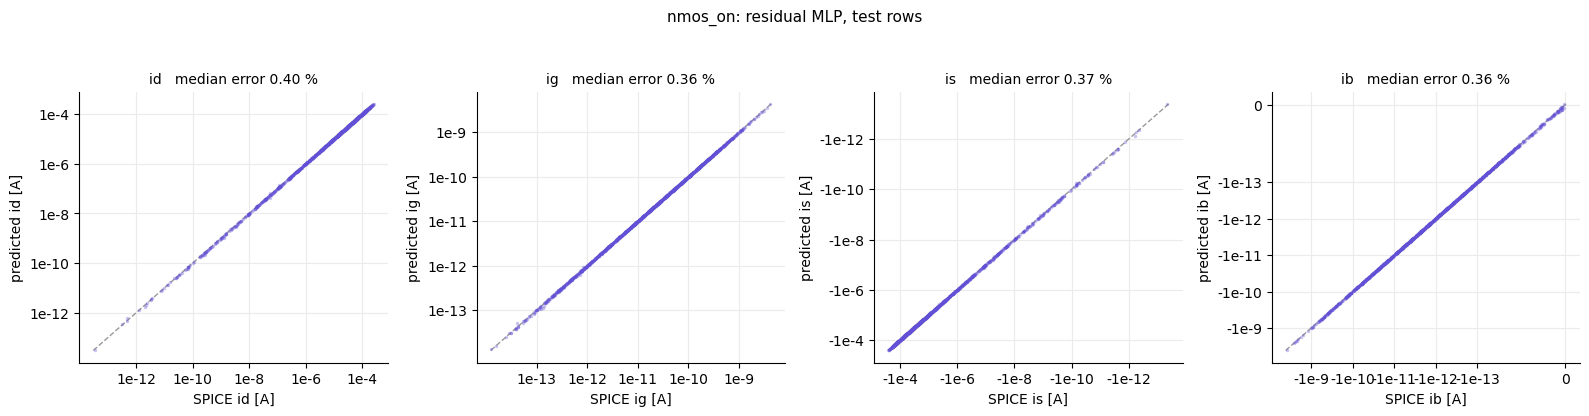

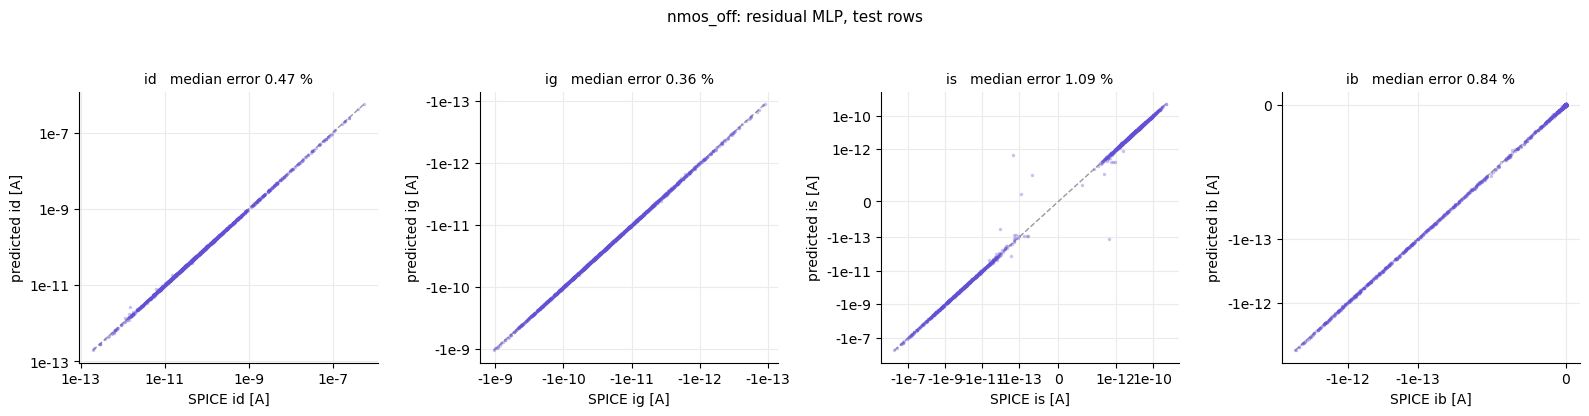

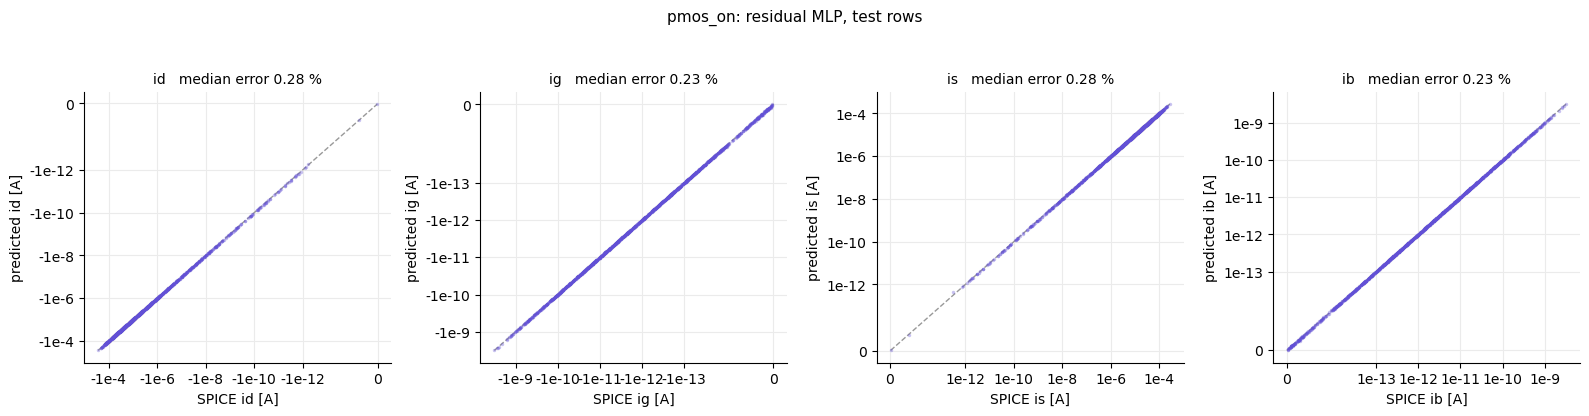

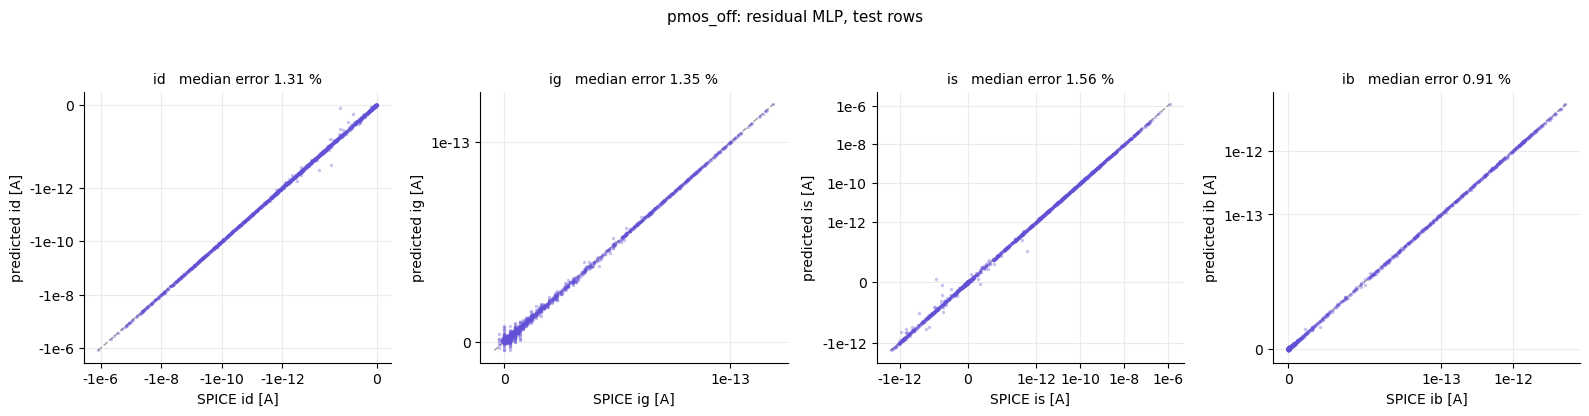

In [33]:
for c in CASES:
    pred_vs_spice(c)

In [34]:
# the saved files are the ones that were scored: reload them once more and compare with the numbers above
chk = []
for c in CASES:
    true, pred, vds = canonical_eval(MODEL_DIR / f"{c}.npz", data[c].iloc[splits[c][2]], c)
    s = score(true, pred, vds, I0)
    chk.append(dict(case=c, median_err_reloaded=s["median_rel"].mean() * 100, median_err_final_table=final.loc[c, "test_median"], p95_reloaded=s["p95_rel"].mean() * 100, p95_final_table=final.loc[c, "test_p95"]))
chk = pd.DataFrame(chk).set_index("case")
assert np.allclose(chk["median_err_reloaded"], chk["median_err_final_table"].astype(float)) and np.allclose(chk["p95_reloaded"], chk["p95_final_table"].astype(float))
chk.round(4)

,median_err_reloaded,median_err_final_table,p95_reloaded,p95_final_table
case,,,,
nmos_on,0.3717,0.3717,2.1862,2.1862
nmos_off,0.6874,0.6874,4.6357,4.6357
pmos_on,0.2552,0.2552,1.3091,1.3091
pmos_off,1.2838,1.2838,11.6841,11.6841


## Summary of the final models (sections 16 and 17)
Test rows, scored once from the saved files in `models/` (1,500 per case; errors in %, each the mean over the four terminals):

| case | version | validation median | test median | test 95th pct | test mean | test R2 (log) |
|---|---|---|---|---|---|---|
| NMOS ON | as chosen | 0.39 | 0.37 | 2.19 | 0.73 | 1.0000 |
| NMOS OFF | refined | 0.74 | 0.69 | 4.64 | 1.62 | 0.9996 |
| PMOS ON | as chosen | 0.24 | 0.26 | 1.31 | 0.45 | 1.0000 |
| PMOS OFF | refined | 1.29 | 1.28 | 11.68 | 3.51 | 0.9996 |

* **The refinement was adopted for both OFF models** (the rule of section 16 holds on the validation rows): on the rail validation set the median error falls from 1.43 % to 0.97 % (NMOS OFF) and from 2.02 % to 1.30 % (PMOS OFF) and the 95th percentile from 43.1 % to 8.5 % and from 26.6 % to 12.8 %; the median error on the uniform validation rows rises by 0.14 and 0.05 percentage points (limit 0.5).
* **The price is a slightly worse score on the uniform samples:** on the uniform test rows the median error goes from 0.60 % to 0.69 % (NMOS OFF) and from 1.21 % to 1.28 % (PMOS OFF), the 95th percentile from 3.84 % to 4.64 % and from 9.31 % to 11.68 %. The models are trained to be accurate where the transistors of a gate operate, near the rails, and the benefit shows at gate level (notebooks 05 and 07 and the report). The ON models are unchanged.
* **Median error below 1 % in three of the four cases, PMOS OFF (1.28 %) above it;** R2 of the signed-log currents is at least 0.9995 in every case (slide target R2 > 0.99).
* **Hardest currents:** `is` of PMOS OFF (median 1.56 %, 95th percentile 15.4 %), `ig` of PMOS OFF (1.35 %, 16.1 %) and `is` of NMOS OFF (1.09 %, 9.7 %): small currents that are sums of components of opposite sign.
* **Small-Vds region (|Vds| < 5 mV, 10 to 23 test rows per terminal):** the median error is 0.33 % to 1.47 % in NMOS ON, NMOS OFF, PMOS ON and the `ig`, `ib` terminals of PMOS OFF, but 26.5 % for `id` and 34.6 % for `is` of PMOS OFF (18 and 17 rows; 14.9 % and 18.4 % before the refinement). The channel term of a device with such a small Vds is weighted by that Vds in the gate leakage, so this does not reach the gate results (notebook 07 section 4).